# Surrogate Modeling of a Particle Transfer Matrix in Phase Space

**Companion notebook to Lecture 1, slides 14 and 15** (*NN Surrogate Example: Particle Transfer Matrix* and *Activation Functions in Beam Transport*).

**Author:** Chong Shik Park, Ph.D. (Korea University, Sejong) &nbsp;·&nbsp; **Date:** November 19, 2026

In linear beam optics a beamline section maps the transverse phase-space coordinates of a particle with a $2 \times 2$ transfer matrix:

$$\begin{pmatrix} x_f \\ x'_f \end{pmatrix} = \mathbf{M} \begin{pmatrix} x_0 \\ x'_0 \end{pmatrix}, \qquad \det \mathbf{M} = 1 .$$

Here we replace $\mathbf{M}$ by a small neural network $f_{\boldsymbol\theta}: \mathbb{R}^2 \to \mathbb{R}^2$, exactly the architecture drawn on slide 14 (two hidden layers of 4 units and a linear output layer):

$$\hat{\mathbf{z}}_f = \mathbf{W}^{(3)}\,\sigma\!\Big(\mathbf{W}^{(2)}\,\sigma\big(\mathbf{W}^{(1)}\mathbf{z}_0 + \mathbf{b}^{(1)}\big) + \mathbf{b}^{(2)}\Big) + \mathbf{b}^{(3)}, \qquad \mathbf{z} = (x, x')^T ,$$

and compare the surrogate with the true matrix **in phase space**: on ellipses, grids, beams and over many passes.
We train three versions that differ only in the hidden activation $\sigma$ (linear, ReLU, tanh) and ask:

1. How accurately does each one reproduce $\mathbf{M}$ inside the training region?
2. How does each one deform phase space, and does it conserve phase-space area ($\det \mathbf{J} = 1$, Liouville's theorem)?
3. What happens outside the training region and over many passes through a periodic lattice?
4. What changes when the true map is **non-linear** (a sextupole kick)?

The whole notebook runs in about a minute on a laptop.

## 0. Setup

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings("ignore", category=UserWarning)   # sklearn convergence notices
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

# One color per model, used in every figure
ACTS = ["identity", "relu", "tanh"]
LABEL = {"exact": "Transfer matrix M", "identity": "NN, linear", "relu": "NN, ReLU", "tanh": "NN, tanh"}
COLOR = {"exact": "black", "identity": "tab:blue", "relu": "tab:orange", "tanh": "tab:green"}
rng = np.random.default_rng(2026)

## 1. The transfer matrix of a FODO cell

We build $\mathbf{M}$ from thin-lens elements: half a focusing quadrupole, a drift, a defocusing quadrupole, a drift and the other half of the focusing quadrupole:

$$\mathbf{M} = \mathbf{Q}\!\left(2f\right)\,\mathbf{D}(L)\,\mathbf{Q}(-f)\,\mathbf{D}(L)\,\mathbf{Q}\!\left(2f\right), \qquad
\mathbf{Q}(f) = \begin{pmatrix} 1 & 0 \\ -1/f & 1 \end{pmatrix}, \quad \mathbf{D}(L) = \begin{pmatrix} 1 & L \\ 0 & 1 \end{pmatrix}.$$

Units: $x$ in mm and $x'$ in mrad. Then $M_{12}$ is in m and $M_{21}$ in 1/m, and both equations stay consistent ($1\text{ m} \times 1\text{ mrad} = 1\text{ mm}$).

Because the cell is periodic, $\mathbf{M}$ can be written in Twiss form,
$\mathbf{M} = \begin{pmatrix} \cos\mu + \alpha\sin\mu & \beta\sin\mu \\ -\gamma\sin\mu & \cos\mu - \alpha\sin\mu \end{pmatrix}$,
which gives the phase advance $\mu$ and the periodic (matched) Twiss parameters $\alpha, \beta, \gamma$.

In [2]:
F_QUAD = 1.6   # quadrupole focal length [m]
L_DRIFT = 1.5  # drift length [m]

def quad(f):
    return np.array([[1.0, 0.0], [-1.0 / f, 1.0]])

def drift(length):
    return np.array([[1.0, length], [0.0, 1.0]])

ELEMENTS = [("QF/2", quad(2 * F_QUAD), 0.0), ("drift", drift(L_DRIFT), L_DRIFT),
            ("QD", quad(-F_QUAD), 0.0), ("drift", drift(L_DRIFT), L_DRIFT), ("QF/2", quad(2 * F_QUAD), 0.0)]

M = np.eye(2)
for _, mat, _ in ELEMENTS:
    M = mat @ M          # later elements multiply from the left

def twiss_from_matrix(m):
    cos_mu = np.trace(m) / 2
    mu = np.arccos(cos_mu)
    sin_mu = np.sign(m[0, 1]) * np.sin(mu)
    beta = m[0, 1] / sin_mu
    alpha = (m[0, 0] - m[1, 1]) / (2 * sin_mu)
    gamma = -m[1, 0] / sin_mu
    return mu, alpha, beta, gamma

MU, ALPHA, BETA, GAMMA = twiss_from_matrix(M)
print("M =\n", np.array2string(M, precision=4))
print(f"det M = {np.linalg.det(M):.12f}   (symplectic: exactly 1)")
print(f"phase advance mu = {np.degrees(MU):.2f} deg,  tune per cell = {MU / (2 * np.pi):.4f}")
print(f"matched Twiss at the cell entrance: beta = {BETA:.3f} m, alpha = {ALPHA:.3f}, gamma = {GAMMA:.4f} 1/m")

M =
 [[ 0.5605  4.4062]
 [-0.1556  0.5605]]
det M = 1.000000000000   (symplectic: exactly 1)
phase advance mu = 55.91 deg,  tune per cell = 0.1553
matched Twiss at the cell entrance: beta = 5.321 m, alpha = 0.000, gamma = 0.1879 1/m


**Figure 1** shows the cell: the beta function along it, the matrix elements, and what one pass does to a beam ellipse.
A *matched* ellipse (shaped by the periodic Twiss parameters) is mapped onto itself; a mismatched one is rotated and sheared, but its area is conserved because $\det\mathbf{M} = 1$.

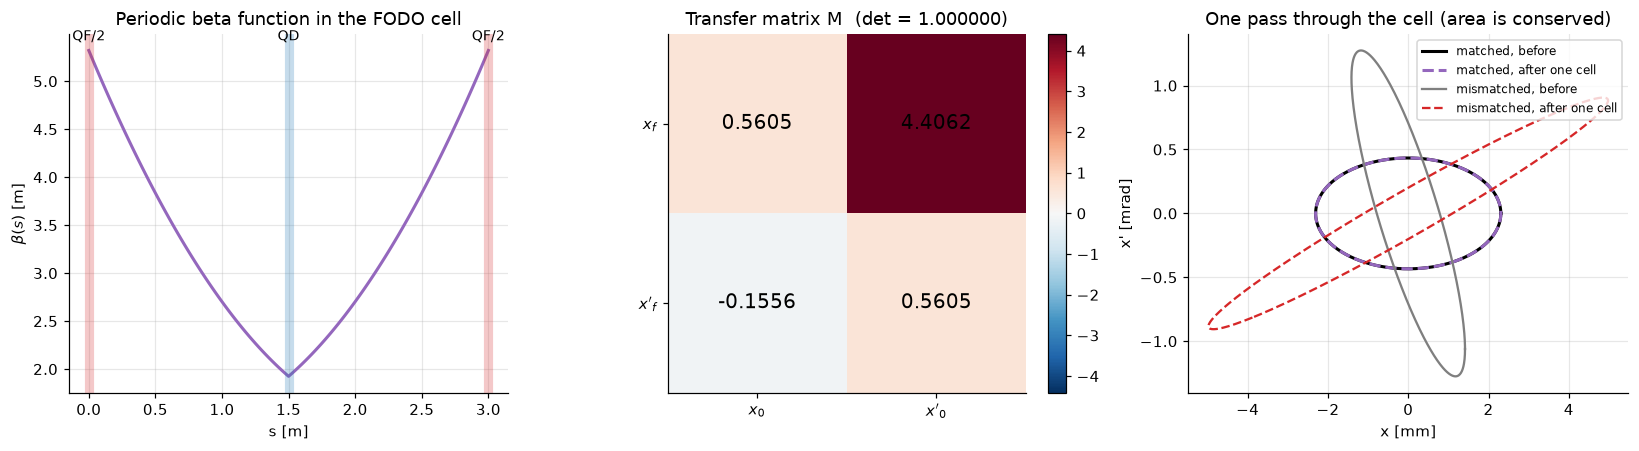

In [3]:
def ellipse(alpha, beta, emittance, n=400):
    # Points on the ellipse gamma x^2 + 2 alpha x x' + beta x'^2 = emittance
    t = np.linspace(0, 2 * np.pi, n)
    x = np.sqrt(emittance * beta) * np.cos(t)
    xp = -np.sqrt(emittance / beta) * (alpha * np.cos(t) + np.sin(t))
    return np.c_[x, xp]

def cs_invariant(z, alpha=ALPHA, beta=BETA, gamma=GAMMA):
    # Courant-Snyder invariant J = gamma x^2 + 2 alpha x x' + beta x'^2 (units: mm mrad)
    x, xp = z[..., 0], z[..., 1]
    return gamma * x**2 + 2 * alpha * x * xp + beta * xp**2

# beta(s) along the cell: transport the Twiss matrix through finely sliced drifts
s_pos, beta_s, s = [0.0], [BETA], 0.0
twiss = np.array([[BETA, -ALPHA], [-ALPHA, GAMMA]])
quad_marks = []
for name, mat, length in ELEMENTS:
    if length == 0:
        twiss = mat @ twiss @ mat.T
        quad_marks.append((s, name))
        beta_s[-1] = twiss[0, 0]
        continue
    for _ in range(60):
        d = drift(length / 60)
        twiss = d @ twiss @ d.T
        s += length / 60
        s_pos.append(s); beta_s.append(twiss[0, 0])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(s_pos, beta_s, color="tab:purple", lw=2)
for s_q, name in quad_marks:
    ax[0].axvline(s_q, color="tab:red" if "QF" in name else "tab:blue", lw=6, alpha=0.25)
    ax[0].text(s_q, max(beta_s) * 1.02, name, ha="center", fontsize=9)
ax[0].set(xlabel="s [m]", ylabel=r"$\beta(s)$ [m]", title="Periodic beta function in the FODO cell")

im = ax[1].imshow(M, cmap="RdBu_r", vmin=-np.abs(M).max(), vmax=np.abs(M).max())
for (i, j), v in np.ndenumerate(M):
    ax[1].text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=13)
ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["$x_0$", "$x'_0$"], yticklabels=["$x_f$", "$x'_f$"],
          title=rf"Transfer matrix M  (det = {np.linalg.det(M):.6f})")
ax[1].grid(False)
plt.colorbar(im, ax=ax[1], fraction=0.046)

eps = 1.0  # emittance [mm mrad]
matched = ellipse(ALPHA, BETA, eps)
mismatched = ellipse(1.5, 2.0, eps)
ax[2].plot(*matched.T, color="black", lw=2, label="matched, before")
ax[2].plot(*(matched @ M.T).T, "--", color="tab:purple", lw=2, label="matched, after one cell")
ax[2].plot(*mismatched.T, color="tab:gray", lw=1.5, label="mismatched, before")
ax[2].plot(*(mismatched @ M.T).T, "--", color="tab:red", lw=1.5, label="mismatched, after one cell")
ax[2].set(xlabel="x [mm]", ylabel="x' [mrad]", title="One pass through the cell (area is conserved)")
ax[2].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 2. Training data: particle tracking pairs

We "track" particles through the cell, i.e. we apply $\mathbf{M}$ to initial coordinates sampled uniformly in a box.
The box is $|x_0| \le 3$ mm and $|x'_0| \le \sqrt{\epsilon\gamma}$, which contains the matched ellipse of emittance $\epsilon = 9/\beta$ mm mrad (the ellipse that reaches $x = 3$ mm).
**Everything outside this box is extrapolation** for the surrogates; the dashed box is drawn in every later figure.

training box: |x0| <= 3.00 mm, |x0'| <= 0.564 mrad   (2000 train / 500 validation pairs)


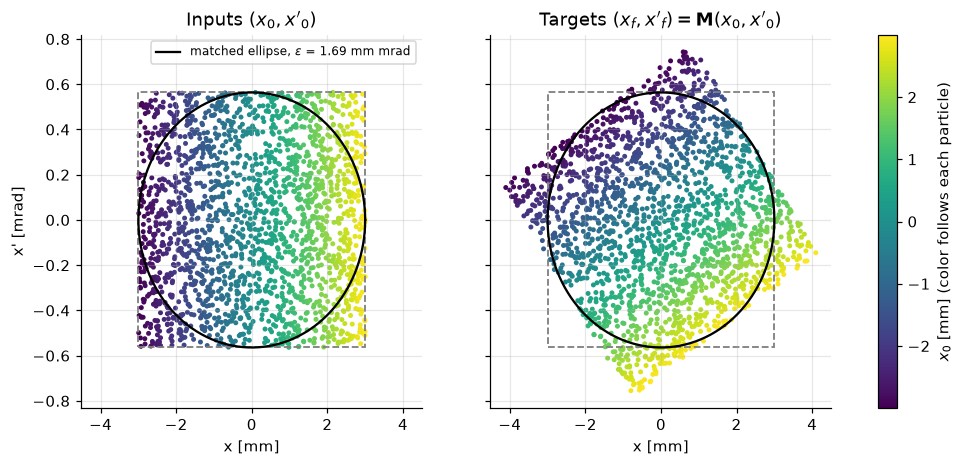

In [4]:
X_HALF = 3.0                                  # mm
EPS_BOX = X_HALF**2 / BETA                    # mm mrad
XP_HALF = np.sqrt(EPS_BOX * GAMMA)            # mrad

def sample_box(n, scale=1.0):
    return np.c_[rng.uniform(-X_HALF, X_HALF, n), rng.uniform(-XP_HALF, XP_HALF, n)] * scale

def track_exact(z):
    return z @ M.T

def add_box(ax, scale=1.0, **kw):
    ax.add_patch(Rectangle((-X_HALF * scale, -XP_HALF * scale), 2 * X_HALF * scale, 2 * XP_HALF * scale,
                           fill=False, ls="--", lw=1.2, color=kw.get("color", "gray")))

Z0_train = sample_box(2000);  Z1_train = track_exact(Z0_train)
Z0_val = sample_box(500);     Z1_val = track_exact(Z0_val)
print(f"training box: |x0| <= {X_HALF:.2f} mm, |x0'| <= {XP_HALF:.3f} mrad   ({len(Z0_train)} train / {len(Z0_val)} validation pairs)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
c = ax[0].scatter(*Z0_train.T, c=Z0_train[:, 0], cmap="viridis", s=5)
ax[0].plot(*ellipse(ALPHA, BETA, EPS_BOX).T, color="k", lw=1.5, label=rf"matched ellipse, $\epsilon$ = {EPS_BOX:.2f} mm mrad")
add_box(ax[0]); ax[0].set(title=r"Inputs $(x_0, x'_0)$", xlabel="x [mm]", ylabel="x' [mrad]"); ax[0].legend(fontsize=8)
ax[1].scatter(*Z1_train.T, c=Z0_train[:, 0], cmap="viridis", s=5)
ax[1].plot(*track_exact(ellipse(ALPHA, BETA, EPS_BOX)).T, color="k", lw=1.5)
add_box(ax[1]); ax[1].set(title=r"Targets $(x_f, x'_f) = \mathbf{M}(x_0, x'_0)$", xlabel="x [mm]")
plt.colorbar(c, ax=ax, label=r"$x_0$ [mm] (color follows each particle)")
plt.show()

## 3. Three surrogates with the slide-14 architecture

All three networks have hidden layers of 4 and 4 units and a linear output layer (scikit-learn's `MLPRegressor` always uses a linear output for regression, which is what slide 15 requires). Only the hidden activation differs.
We train with the full-batch quasi-Newton solver `lbfgs`, which suits a small, noise-free dataset, and record the training dynamics separately with Adam in the next figure.

We also need the **Jacobian** $\mathbf{J} = \partial \hat{\mathbf{z}}_f / \partial \mathbf{z}_0$ of each network: for the true map $\mathbf{J} = \mathbf{M}$ everywhere and $\det\mathbf{J} = 1$. The helper below computes it exactly with the chain rule.

In [5]:
HIDDEN = (4, 4)

def make_mlp(act, hidden=HIDDEN, seed=1, **kw):
    params = dict(hidden_layer_sizes=hidden, activation=act, solver="lbfgs", alpha=0.0,
                  max_iter=5000, tol=1e-12, random_state=seed)
    params.update(kw)
    return MLPRegressor(**params)

def forward_with_jacobian(model, z):
    # Return predictions, Jacobians (n, 2, 2) and hidden pre-activations for points z (n, 2)
    h = np.atleast_2d(z)
    jac = np.broadcast_to(np.eye(2), (len(h), 2, 2)).copy()
    pre = []
    n_layers = len(model.coefs_)
    for i, (W, b) in enumerate(zip(model.coefs_, model.intercepts_)):
        a = h @ W + b
        if i < n_layers - 1:
            pre.append(a)
            if model.activation == "relu":
                h, d = np.maximum(a, 0), (a > 0).astype(float)
            elif model.activation == "tanh":
                h = np.tanh(a); d = 1 - h**2
            else:
                h, d = a, np.ones_like(a)
            jac = d[:, :, None] * np.einsum("ji,njk->nik", W, jac)   # diag(sigma'(a)) W^T J
        else:
            h = a
            jac = np.einsum("ji,njk->nik", W, jac)
    return h, jac, pre

models = {}
for act in ACTS:
    t0 = time.time()
    models[act] = make_mlp(act).fit(Z0_train, Z1_train)
    pred = models[act].predict(Z0_val)
    rmse = np.sqrt(np.mean((pred - Z1_val) ** 2))
    _, J, _ = forward_with_jacobian(models[act], Z0_val)
    detJ = np.linalg.det(J)
    print(f"{LABEL[act]:11s}  validation RMSE = {rmse:.2e}   det J in box: {detJ.mean():.4f} +/- {detJ.std():.4f}"
          f"   ({models[act].n_iter_} iterations, {time.time() - t0:.1f} s)")

# Sanity check of the analytic Jacobian against finite differences
z_test, h_fd = Z0_val[:5], 1e-5
for act in ACTS:
    _, J, _ = forward_with_jacobian(models[act], z_test)
    fd = np.stack([(models[act].predict(z_test + h_fd * e) - models[act].predict(z_test - h_fd * e)) / (2 * h_fd)
                   for e in np.eye(2)], axis=-1)
    assert np.allclose(J, fd, atol=1e-4), act
print("analytic Jacobians agree with finite differences")

NN, linear   validation RMSE = 1.39e-06   det J in box: 1.0000 +/- 0.0000   (20 iterations, 0.0 s)
NN, ReLU     validation RMSE = 2.96e-05   det J in box: 0.9999 +/- 0.0001   (127 iterations, 0.1 s)


NN, tanh     validation RMSE = 4.00e-03   det J in box: 0.9974 +/- 0.0205   (356 iterations, 0.2 s)
analytic Jacobians agree with finite differences


**Figure 3: training dynamics.** To see *how* each network learns, we train fresh copies with the Adam optimizer one epoch at a time (`partial_fit`) and record the training and validation error. The linear network reaches round-off level within about 40 epochs because the target is linear (training it much longer with Adam eventually becomes numerically unstable, so we stop at 250 epochs). The non-linear networks must *approximate* a linear map with curved or kinked pieces and stall at a finite error.

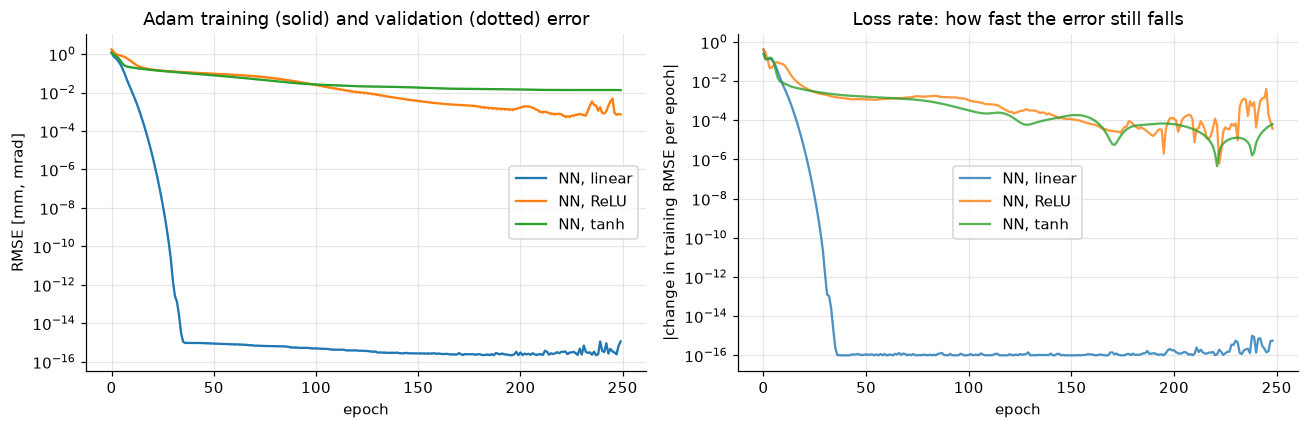

NN, linear  Adam after 250 epochs: validation RMSE 1.14e-15   |   lbfgs model: 1.39e-06
NN, ReLU    Adam after 250 epochs: validation RMSE 7.36e-04   |   lbfgs model: 2.96e-05
NN, tanh    Adam after 250 epochs: validation RMSE 1.36e-02   |   lbfgs model: 4.00e-03


In [6]:
def training_curve(act, epochs=250, seed=1):
    m = MLPRegressor(hidden_layer_sizes=HIDDEN, activation=act, solver="adam", learning_rate_init=3e-3,
                     batch_size=64, alpha=0.0, random_state=seed)
    tr, va = [], []
    for _ in range(epochs):
        m.partial_fit(Z0_train, Z1_train)
        tr.append(np.sqrt(np.mean((m.predict(Z0_train) - Z1_train) ** 2)))
        va.append(np.sqrt(np.mean((m.predict(Z0_val) - Z1_val) ** 2)))
    return np.array(tr), np.array(va)

curves = {act: training_curve(act) for act in ACTS}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for act in ACTS:
    tr, va = curves[act]
    ax[0].semilogy(tr, color=COLOR[act], label=LABEL[act])
    ax[0].semilogy(va, color=COLOR[act], ls=":", lw=1)
    ax[1].semilogy(np.abs(np.diff(tr)) + 1e-16, color=COLOR[act], alpha=0.8, label=LABEL[act])
ax[0].set(xlabel="epoch", ylabel="RMSE [mm, mrad]", title="Adam training (solid) and validation (dotted) error")
ax[1].set(xlabel="epoch", ylabel="|change in training RMSE per epoch|", title="Loss rate: how fast the error still falls")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()
for act in ACTS:
    print(f"{LABEL[act]:11s} Adam after 250 epochs: validation RMSE {curves[act][1][-1]:.2e}"
          f"   |   lbfgs model: {np.sqrt(np.mean((models[act].predict(Z0_val) - Z1_val) ** 2)):.2e}")

## 4. Accuracy inside the training region

**Figure 4** compares predicted and true final coordinates for the validation particles (parity plots), and **Figure 5** shows the distribution of the errors.

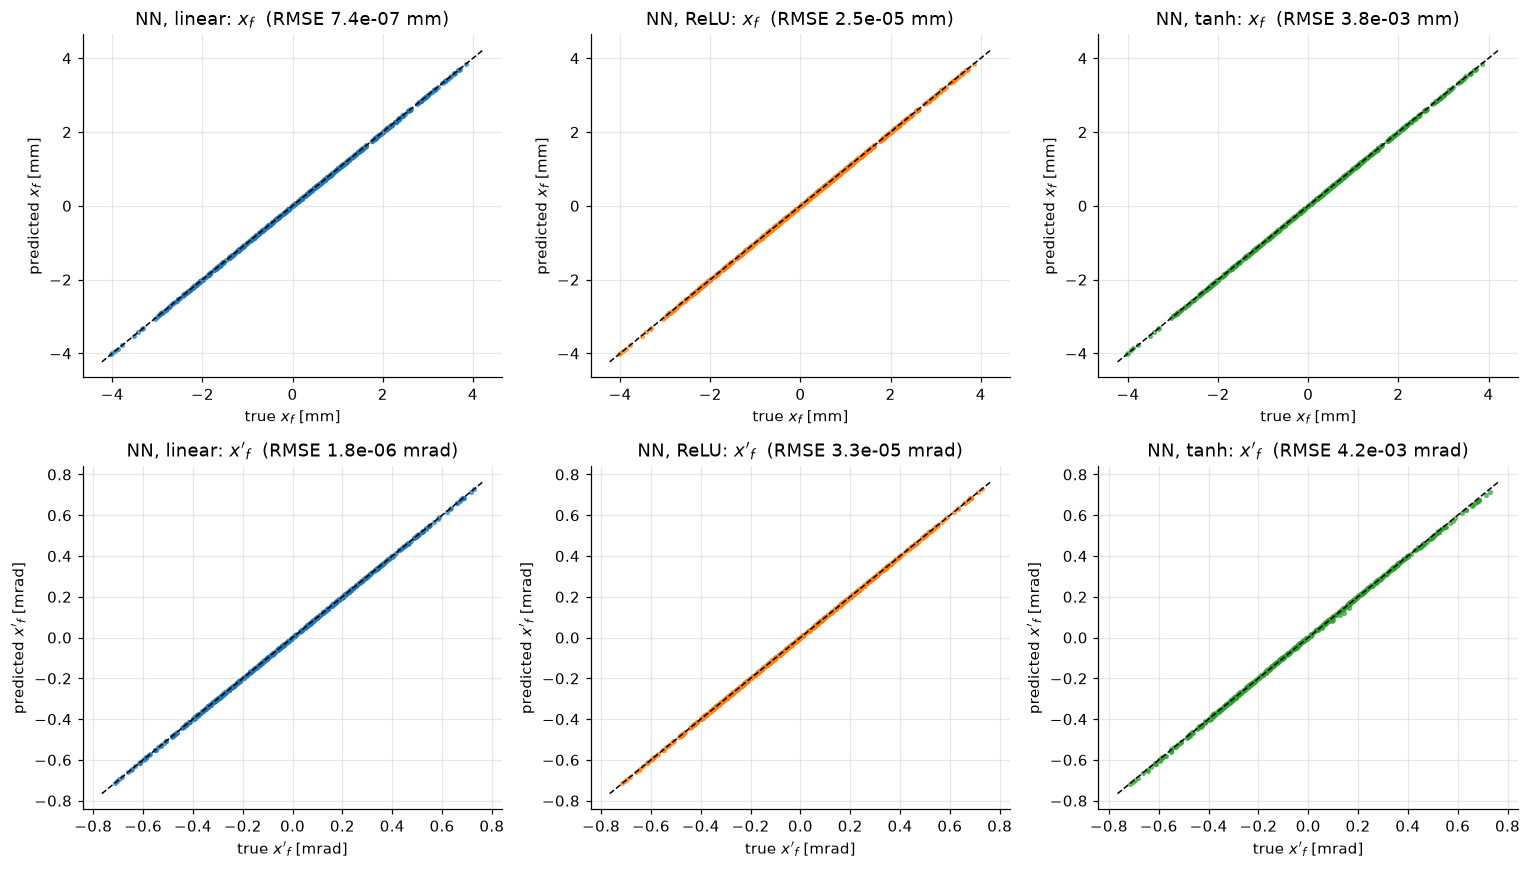

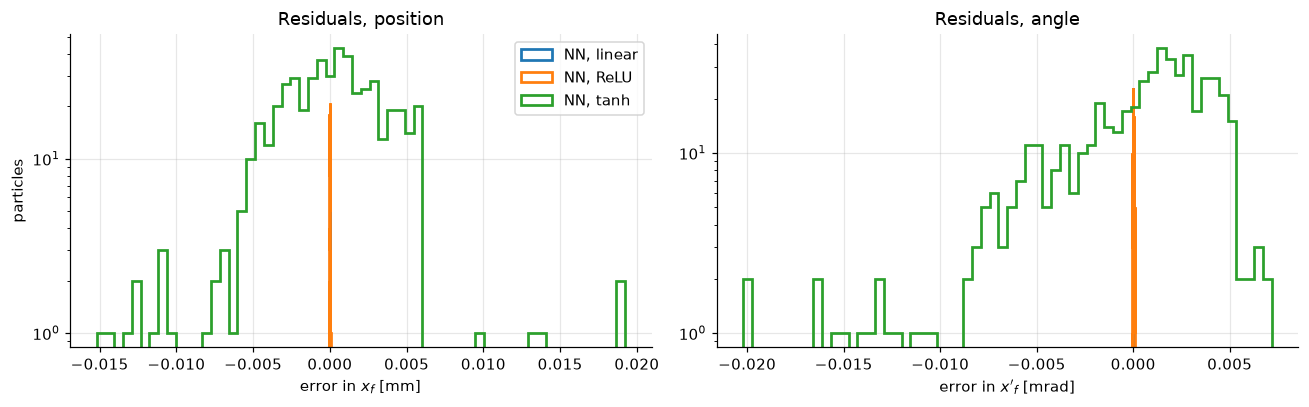

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for k, act in enumerate(ACTS):
    pred = models[act].predict(Z0_val)
    for r, (name, unit) in enumerate([("x_f", "mm"), ("x'_f", "mrad")]):
        a = ax[r, k]
        a.scatter(Z1_val[:, r], pred[:, r], s=6, color=COLOR[act], alpha=0.6)
        lim = np.abs(Z1_val[:, r]).max() * 1.05
        a.plot([-lim, lim], [-lim, lim], "k--", lw=1)
        err = np.sqrt(np.mean((pred[:, r] - Z1_val[:, r]) ** 2))
        a.set(xlabel=f"true ${name}$ [{unit}]", ylabel=f"predicted ${name}$ [{unit}]",
              title=f"{LABEL[act]}: ${name}$  (RMSE {err:.1e} {unit})")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for act in ACTS:
    res = models[act].predict(Z0_val) - Z1_val
    for r in range(2):
        ax[r].hist(res[:, r], bins=60, histtype="step", lw=1.8, color=COLOR[act], label=LABEL[act], log=True)
ax[0].set(xlabel=r"error in $x_f$ [mm]", ylabel="particles", title="Residuals, position")
ax[1].set(xlabel=r"error in $x'_f$ [mrad]", title="Residuals, angle")
ax[0].legend(); plt.tight_layout(); plt.show()

**Figure 6: sensitivity to the random initialization.** The networks above were trained from one random seed. Here we retrain each architecture from 10 seeds. The linear and tanh networks land near the same error every time. The small ReLU network does not: its error spans five orders of magnitude between seeds. Most seeds end with "dead" units, which are inactive for every training particle; their gradient is zero, so they never recover. Dead units alone do not decide the outcome (the best seed has three), but with only 4 units per layer there is no spare capacity, and whether the surviving units can still represent the rotation of phase space depends on the starting point. A good validation score from one seed says little about a small ReLU network.

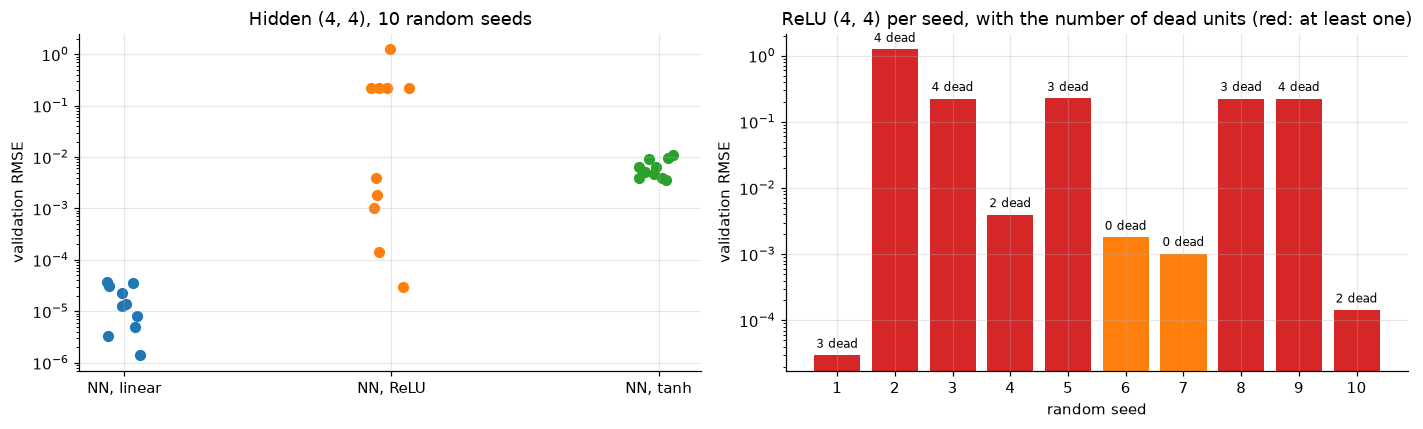

NN, linear  median 1.3e-05, best 1.4e-06, worst 3.8e-05
NN, ReLU    median 1.1e-01, best 3.0e-05, worst 1.2e+00
NN, tanh    median 5.7e-03, best 3.6e-03, worst 1.1e-02


In [8]:
SEEDS = range(1, 11)
seed_err, dead_units = {}, {}
for act in ACTS:
    seed_err[act], dead_units[act] = [], []
    for sd in SEEDS:
        m = make_mlp(act, seed=sd).fit(Z0_train, Z1_train)
        seed_err[act].append(np.sqrt(np.mean((m.predict(Z0_val) - Z1_val) ** 2)))
        _, _, pre = forward_with_jacobian(m, Z0_train)
        dead_units[act].append(int(sum((p <= 0).all(axis=0).sum() for p in pre)) if act == "relu" else 0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, act in enumerate(ACTS):
    ax[0].scatter(np.full(len(SEEDS), k) + rng.uniform(-0.08, 0.08, len(SEEDS)), seed_err[act], color=COLOR[act], s=40)
ax[0].set(yscale="log", xticks=range(len(ACTS)), xticklabels=[LABEL[a] for a in ACTS], ylabel="validation RMSE",
          title="Hidden (4, 4), 10 random seeds")
cols = ["tab:red" if d > 0 else COLOR["relu"] for d in dead_units["relu"]]
ax[1].bar([str(sd) for sd in SEEDS], seed_err["relu"], color=cols)
for i, d in enumerate(dead_units["relu"]):
    ax[1].text(i, seed_err["relu"][i] * 1.3, f"{d} dead", ha="center", fontsize=8)
ax[1].set(yscale="log", xlabel="random seed", ylabel="validation RMSE", title="ReLU (4, 4) per seed, with the number of dead units (red: at least one)")
plt.tight_layout(); plt.show()
for act in ACTS:
    e = np.array(seed_err[act])
    print(f"{LABEL[act]:11s} median {np.median(e):.1e}, best {e.min():.1e}, worst {e.max():.1e}")

## 5. What did the linear network learn?

With $\sigma(z) = z$ the network is $\hat{\mathbf{z}}_f = \mathbf{W}^{(3)}\mathbf{W}^{(2)}\mathbf{W}^{(1)}\mathbf{z}_0 + \mathbf{b}_{\text{net}}$: the three layers **collapse into a single matrix** (slide 15). We can read that matrix off the weights and compare it with $\mathbf{M}$ (**Figure 7**). The individual weight matrices are not unique (many factorizations give the same product), but their product is $\mathbf{M}$.

Note on conventions: scikit-learn stores each layer as `coefs_[i]` with shape (inputs, outputs), i.e. the transpose of $\mathbf{W}^{(i)}$ in the slide's notation.

Effective matrix W3 W2 W1 =
 [[ 0.560547  4.406248]
 [-0.155639  0.56055 ]]
True M =
 [[ 0.560547  4.40625 ]
 [-0.15564   0.560547]]
max |M_eff - M| = 3.35e-06,  det M_eff = 0.99999941,  b_net = [-2.17e-07  1.10e-06]


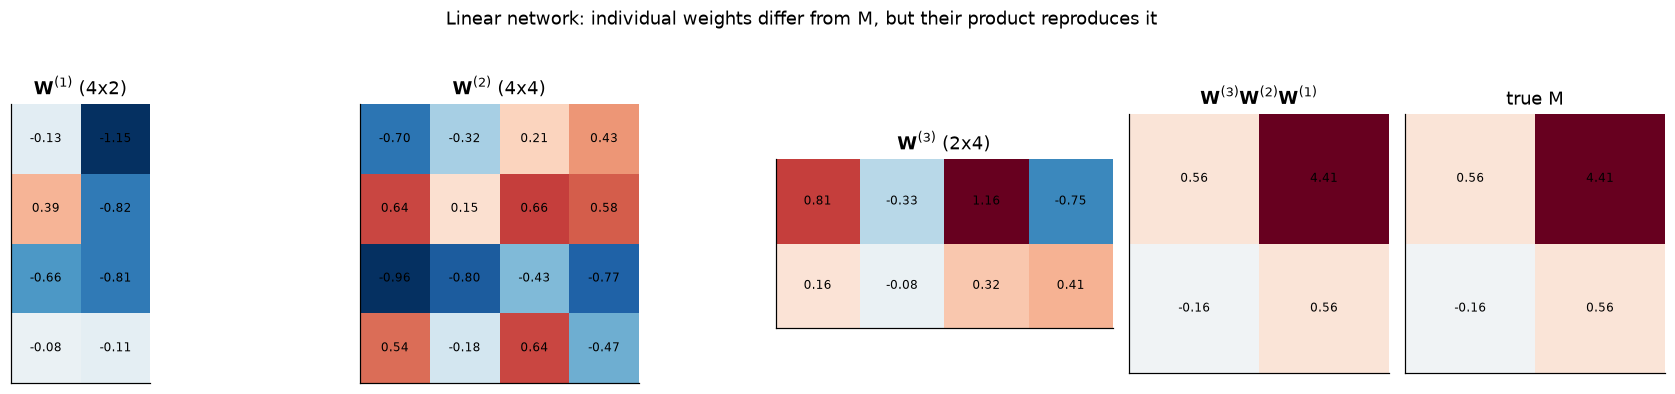

In [9]:
lin = models["identity"]
W = [w.T for w in lin.coefs_]               # slide notation: W^(1): 4x2, W^(2): 4x4, W^(3): 2x4
M_eff = W[2] @ W[1] @ W[0]
b_net = W[2] @ (W[1] @ lin.intercepts_[0] + lin.intercepts_[1]) + lin.intercepts_[2]
print("Effective matrix W3 W2 W1 =\n", np.array2string(M_eff, precision=6))
print("True M =\n", np.array2string(M, precision=6))
print(f"max |M_eff - M| = {np.abs(M_eff - M).max():.2e},  det M_eff = {np.linalg.det(M_eff):.8f},  b_net = {np.array2string(b_net, precision=2)}")

fig, ax = plt.subplots(1, 5, figsize=(16, 3.4), gridspec_kw={"width_ratios": [1.1, 2, 1.3, 1, 1]})
for a, mat, title in zip(ax, [W[0], W[1], W[2], M_eff, M],
                         [r"$\mathbf{W}^{(1)}$ (4x2)", r"$\mathbf{W}^{(2)}$ (4x4)", r"$\mathbf{W}^{(3)}$ (2x4)",
                          r"$\mathbf{W}^{(3)}\mathbf{W}^{(2)}\mathbf{W}^{(1)}$", "true M"]):
    v = np.abs(mat).max()
    a.imshow(mat, cmap="RdBu_r", vmin=-v, vmax=v)
    for (i, j), val in np.ndenumerate(mat):
        a.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)
    a.set_title(title); a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.suptitle("Linear network: individual weights differ from M, but their product reproduces it", y=1.04)
plt.tight_layout(); plt.show()

## 6. Phase-space geometry: ellipses and grids

Now the central comparison of slide 15. **Figure 8** maps matched ellipses of increasing size: one inside the training box, one at its edge, and two beyond it (2x and 3x the training amplitude).
Under $\mathbf{M}$ a matched ellipse maps onto itself. Any deviation is surrogate error.

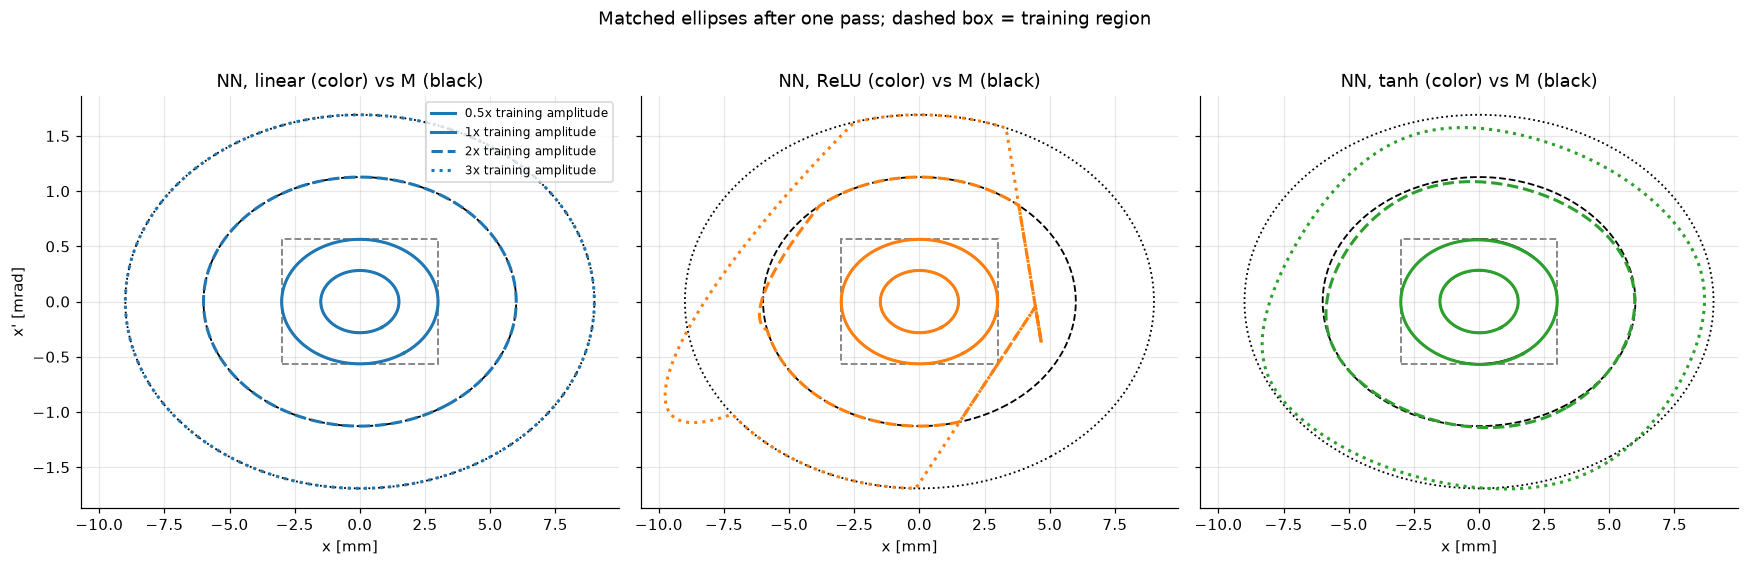

In [10]:
scales = [0.5, 1.0, 2.0, 3.0]
fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for k, act in enumerate(ACTS):
    a = ax[k]
    for s, ls in zip(scales, ["-", "-", "--", ":"]):
        e0 = ellipse(ALPHA, BETA, EPS_BOX * s**2)
        a.plot(*track_exact(e0).T, color="black", lw=1.2, ls=ls)
        a.plot(*models[act].predict(e0).T, color=COLOR[act], lw=2, ls=ls, label=f"{s:g}x training amplitude")
    add_box(a)
    a.set(title=f"{LABEL[act]} (color) vs M (black)", xlabel="x [mm]")
    a.set_aspect("auto")
ax[0].set_ylabel("x' [mrad]"); ax[0].legend(fontsize=8, loc="upper right")
plt.suptitle("Matched ellipses after one pass; dashed box = training region", y=1.02)
plt.tight_layout(); plt.show()

**Figure 9** maps a regular grid of initial conditions (covering twice the training box) and draws the image of every grid line. The true map sends straight lines to straight lines (a sheared, rotated grid). The ReLU network bends lines at the hyperplanes where a hidden unit switches on or off (**faceted polygons with kinks**), and the tanh network bends them smoothly, increasingly far from the training region (**S-curves from saturation**).

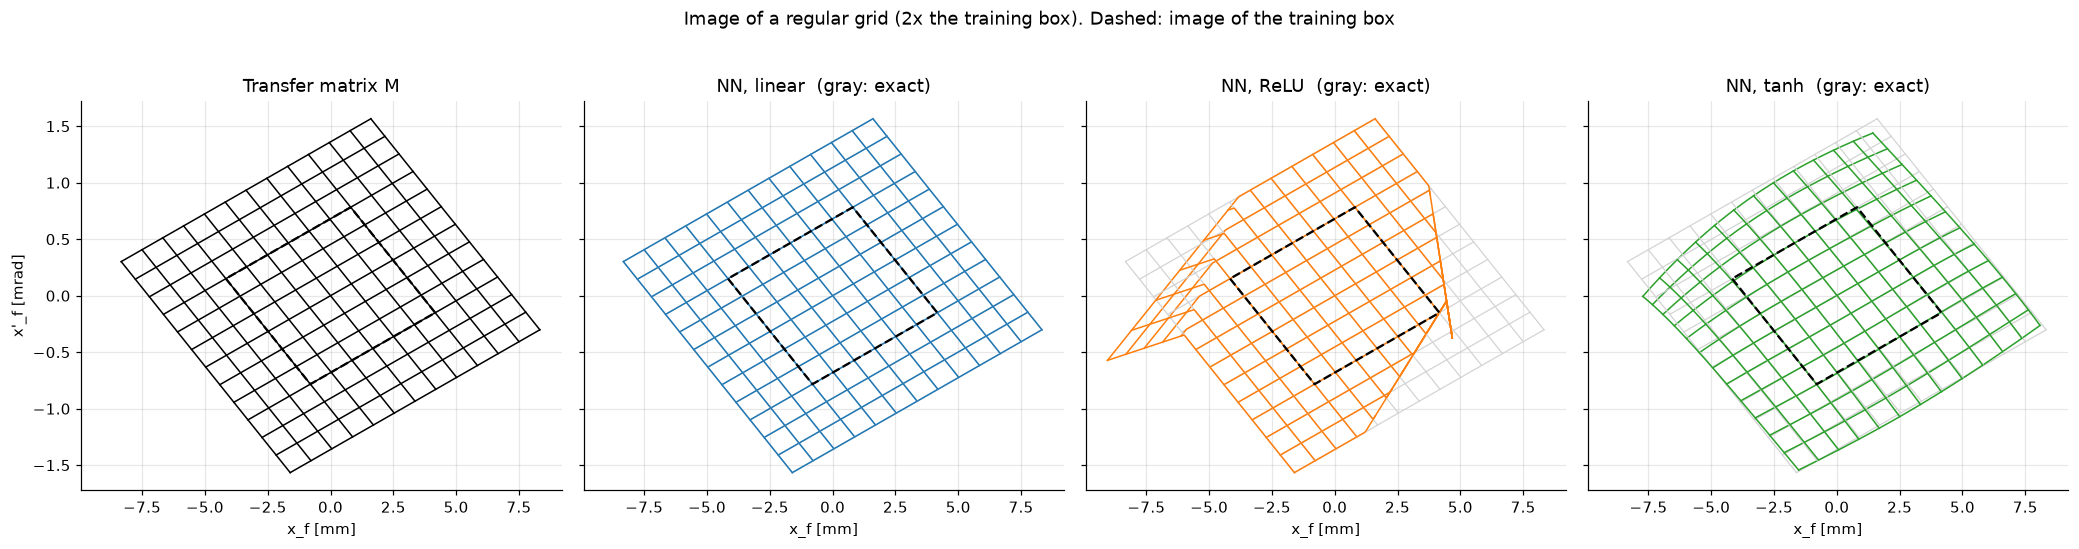

In [11]:
def grid_lines(scale=2.0, n_lines=13, n_pts=200):
    xs = np.linspace(-X_HALF * scale, X_HALF * scale, n_lines)
    ps = np.linspace(-XP_HALF * scale, XP_HALF * scale, n_lines)
    t_x = np.linspace(-X_HALF * scale, X_HALF * scale, n_pts)
    t_p = np.linspace(-XP_HALF * scale, XP_HALF * scale, n_pts)
    lines = [np.c_[np.full(n_pts, x), t_p] for x in xs] + [np.c_[t_x, np.full(n_pts, p)] for p in ps]
    return lines

lines = grid_lines()
fig, ax = plt.subplots(1, 4, figsize=(19, 4.8), sharex=True, sharey=True)
for a, key in zip(ax, ["exact"] + ACTS):
    for ln in lines:
        img = track_exact(ln) if key == "exact" else models[key].predict(ln)
        if key != "exact":
            a.plot(*track_exact(ln).T, color="lightgray", lw=0.8)
        a.plot(*img.T, color=COLOR[key], lw=1)
    a.plot(*track_exact(np.array([[-X_HALF, -XP_HALF], [X_HALF, -XP_HALF], [X_HALF, XP_HALF], [-X_HALF, XP_HALF], [-X_HALF, -XP_HALF]])).T,
           "k--", lw=1.5)
    a.set(title=f"{LABEL[key]}" + ("" if key == "exact" else "  (gray: exact)"), xlabel="x_f [mm]")
ax[0].set_ylabel("x'_f [mrad]")
plt.suptitle("Image of a regular grid (2x the training box). Dashed: image of the training box", y=1.03)
plt.tight_layout(); plt.show()

## 7. Where is each surrogate wrong? Error maps and extrapolation

**Figure 10** shows $\log_{10}$ of the prediction error $\|f_{\boldsymbol\theta}(\mathbf{z}_0) - \mathbf{M}\mathbf{z}_0\|$ over a region three times larger than the training box (dashed).
**Figure 11** averages the error over matched ellipses of growing amplitude.

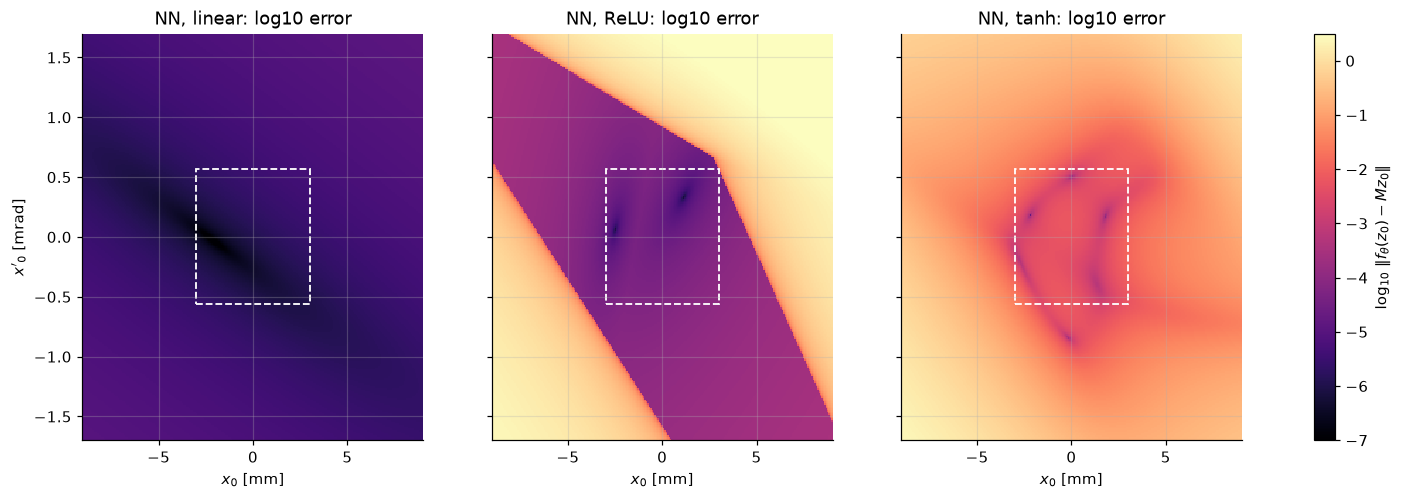

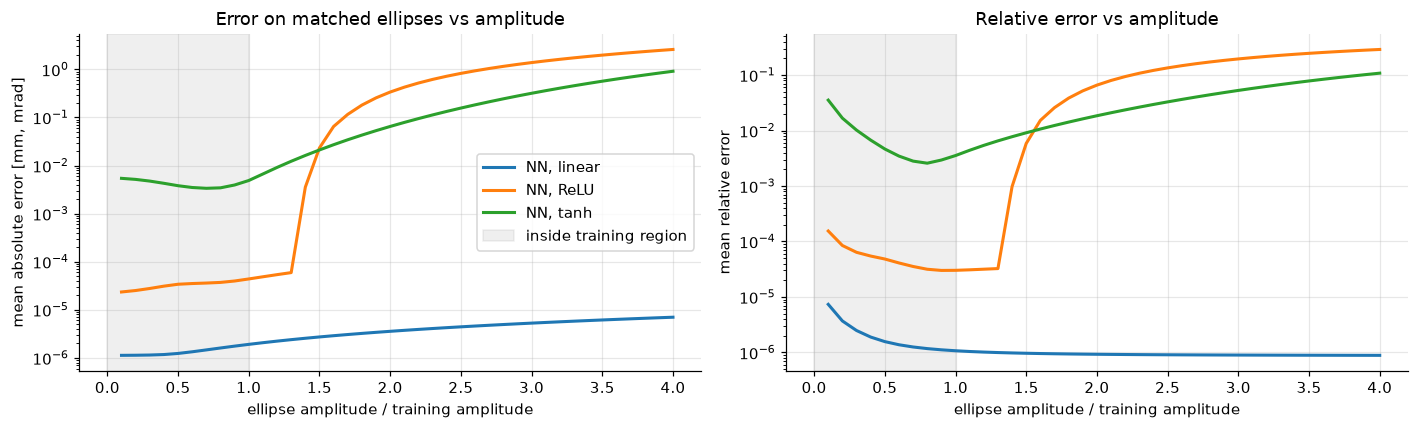

In [12]:
def phase_grid(scale=3.0, n=241):
    xs = np.linspace(-X_HALF * scale, X_HALF * scale, n)
    ps = np.linspace(-XP_HALF * scale, XP_HALF * scale, n)
    XX, PP = np.meshgrid(xs, ps)
    return XX, PP, np.c_[XX.ravel(), PP.ravel()]

XX, PP, ZG = phase_grid()
exact_G = track_exact(ZG)
err_maps = {act: np.linalg.norm(models[act].predict(ZG) - exact_G, axis=1).reshape(XX.shape) for act in ACTS}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for a, act in zip(ax, ACTS):
    im = a.pcolormesh(XX, PP, np.log10(err_maps[act] + 1e-12), cmap="magma", vmin=-7, vmax=0.5, shading="auto")
    add_box(a, color="white")
    a.set(title=f"{LABEL[act]}: log10 error", xlabel="$x_0$ [mm]")
ax[0].set_ylabel("$x'_0$ [mrad]")
plt.colorbar(im, ax=ax, label=r"$\log_{10}\,\|f_\theta(z_0) - M z_0\|$")
plt.show()

amps = np.linspace(0.1, 4.0, 40)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for act in ACTS:
    abs_err, rel_err = [], []
    for s in amps:
        e0 = ellipse(ALPHA, BETA, EPS_BOX * s**2, n=200)
        d = np.linalg.norm(models[act].predict(e0) - track_exact(e0), axis=1)
        abs_err.append(d.mean()); rel_err.append((d / np.linalg.norm(track_exact(e0), axis=1)).mean())
    ax[0].semilogy(amps, abs_err, color=COLOR[act], lw=2, label=LABEL[act])
    ax[1].semilogy(amps, rel_err, color=COLOR[act], lw=2, label=LABEL[act])
for a in ax:
    a.axvspan(0, 1, color="gray", alpha=0.12, label="inside training region")
    a.set_xlabel("ellipse amplitude / training amplitude")
ax[0].set(ylabel="mean absolute error [mm, mrad]", title="Error on matched ellipses vs amplitude")
ax[1].set(ylabel="mean relative error", title="Relative error vs amplitude")
ax[0].legend(); plt.tight_layout(); plt.show()

## 8. Symplecticity: does the surrogate conserve phase-space area?

Liouville's theorem requires $\det \mathbf{J} = 1$ for every particle. **Figure 12** maps $\det\mathbf{J}$ over phase space (white = 1, red > 1 expands area, blue < 1 compresses it) and **Figure 13** shows its distribution. Where fewer than two ReLU units of a hidden layer are active, the network can no longer pass on two independent directions, so $\det\mathbf{J} = 0$: the map collapses a whole area onto a line. For the tanh network, $\det\mathbf{J}$ drifts smoothly away from 1 as the units saturate.

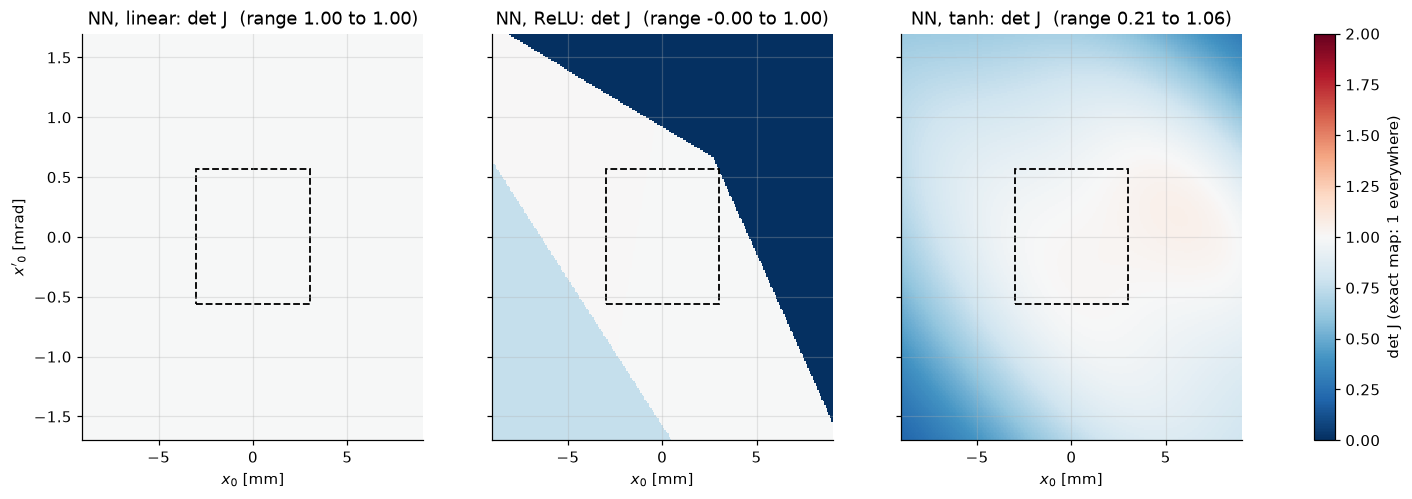

NN, linear  det J inside box: mean 1.00000, max |det J - 1| = 5.92e-07;  outside: min 1.000, max 1.000, fraction with det J = 0: 0.0%
NN, ReLU    det J inside box: mean 0.99979, max |det J - 1| = 1.00e+00;  outside: min -0.000, max 1.000, fraction with det J = 0: 25.1%
NN, tanh    det J inside box: mean 0.99557, max |det J - 1| = 7.89e-02;  outside: min 0.207, max 1.056, fraction with det J = 0: 0.0%


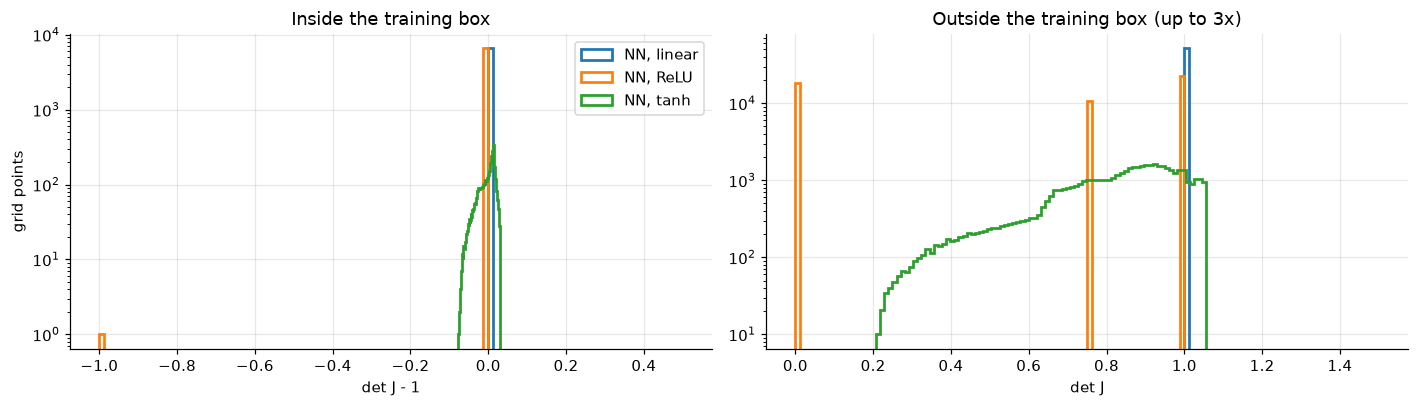

In [13]:
detJ_maps = {}
for act in ACTS:
    _, J, _ = forward_with_jacobian(models[act], ZG)
    detJ_maps[act] = np.linalg.det(J).reshape(XX.shape)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for a, act in zip(ax, ACTS):
    im = a.pcolormesh(XX, PP, detJ_maps[act], cmap="RdBu_r", vmin=0, vmax=2, shading="auto")
    add_box(a, color="black")
    a.set(title=f"{LABEL[act]}: det J  (range {detJ_maps[act].min():.2f} to {detJ_maps[act].max():.2f})", xlabel="$x_0$ [mm]")
ax[0].set_ylabel("$x'_0$ [mrad]")
plt.colorbar(im, ax=ax, label="det J (exact map: 1 everywhere)")
plt.show()

inside = (np.abs(ZG[:, 0]) <= X_HALF) & (np.abs(ZG[:, 1]) <= XP_HALF)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for act in ACTS:
    d_in = detJ_maps[act].ravel()[inside]
    d_out = detJ_maps[act].ravel()[~inside]
    ax[0].hist(d_in - 1, bins=80, histtype="step", lw=1.8, color=COLOR[act], label=LABEL[act], log=True)
    ax[1].hist(d_out, bins=80, histtype="step", lw=1.8, color=COLOR[act], label=LABEL[act], log=True)
    print(f"{LABEL[act]:11s} det J inside box: mean {d_in.mean():.5f}, max |det J - 1| = {np.abs(d_in - 1).max():.2e};"
          f"  outside: min {d_out.min():.3f}, max {d_out.max():.3f}, fraction with det J = 0: {(np.abs(d_out) < 1e-9).mean():.1%}")
ax[0].set(xlabel="det J - 1", ylabel="grid points", title="Inside the training box")
ax[1].set(xlabel="det J", title="Outside the training box (up to 3x)")
ax[0].legend(); plt.tight_layout(); plt.show()

**Figure 14: what the hidden units are doing.** Left: the ReLU network divides phase space into regions with a fixed on/off pattern of its 8 hidden units; inside each region the map is exactly affine, and the region boundaries are the kinks seen in Figure 9. Right: for the tanh network, the largest $|\tanh|$ among its hidden units. Where it approaches 1 the units saturate, the map flattens, and $\det\mathbf{J}$ drops toward 0.

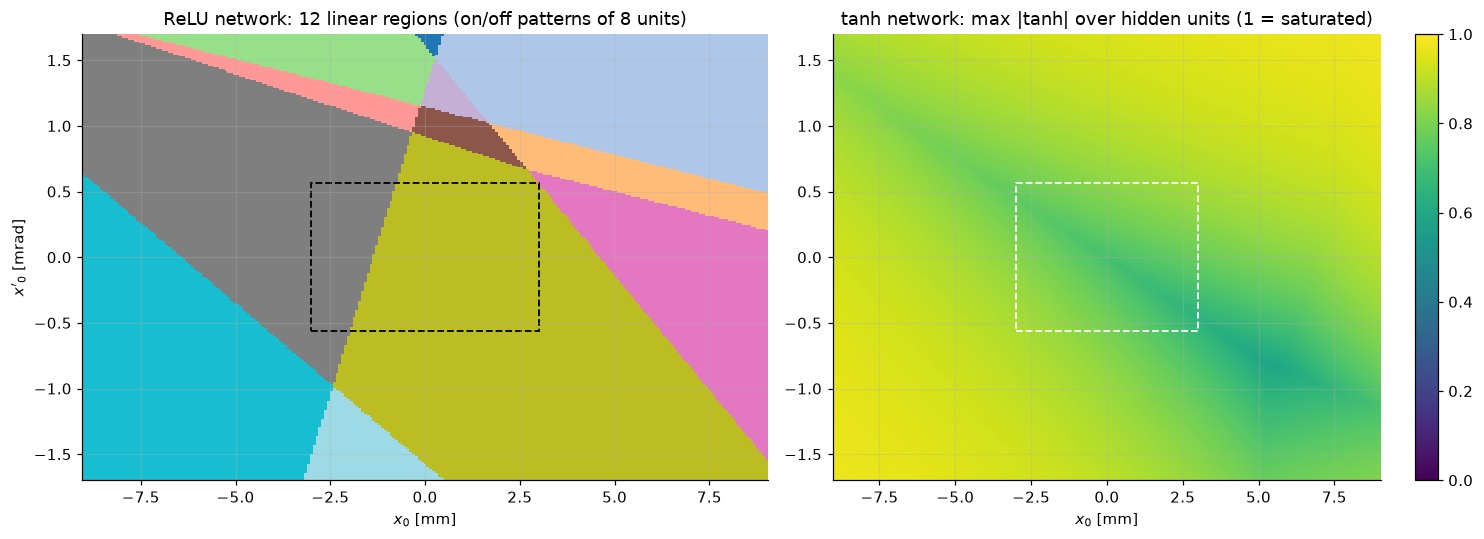

In [14]:
_, _, pre_relu = forward_with_jacobian(models["relu"], ZG)
pattern = np.hstack([(p > 0) for p in pre_relu]).astype(int) @ (2 ** np.arange(8))
uniq, region_id = np.unique(pattern, return_inverse=True)
_, _, pre_tanh = forward_with_jacobian(models["tanh"], ZG)
sat = np.max(np.abs(np.tanh(np.hstack(pre_tanh))), axis=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cmap = plt.get_cmap("tab20", len(uniq))
ax[0].pcolormesh(XX, PP, region_id.reshape(XX.shape), cmap=cmap, shading="auto")
add_box(ax[0], color="black")
ax[0].set(title=f"ReLU network: {len(uniq)} linear regions (on/off patterns of 8 units)", xlabel="$x_0$ [mm]", ylabel="$x'_0$ [mrad]")
im = ax[1].pcolormesh(XX, PP, sat.reshape(XX.shape), cmap="viridis", vmin=0, vmax=1, shading="auto")
add_box(ax[1], color="white")
ax[1].set(title="tanh network: max |tanh| over hidden units (1 = saturated)", xlabel="$x_0$ [mm]")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

## 9. Many passes: tracking through a periodic lattice

A FODO cell is usually repeated. Tracking a particle through $N$ cells means applying the map $N$ times, so a small error per pass can accumulate. With the exact $\mathbf{M}$ a particle stays on its ellipse (the Courant-Snyder invariant $J = \gamma x^2 + 2\alpha x x' + \beta x'^2$ is constant). **Figure 15** shows Poincaré plots of 300 passes for three particles started at 0.5x, 0.9x and 1.5x the training amplitude; **Figure 16** shows how $J$ evolves.

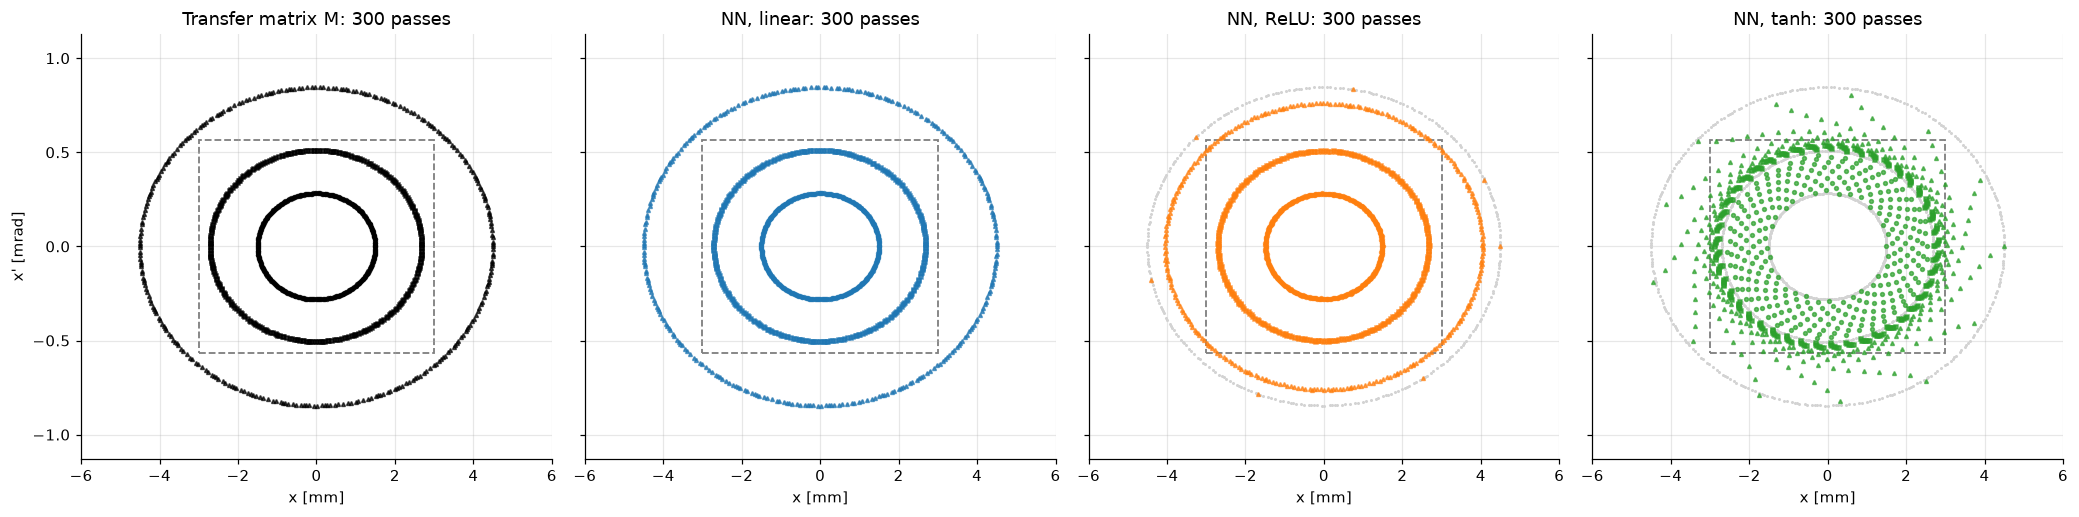

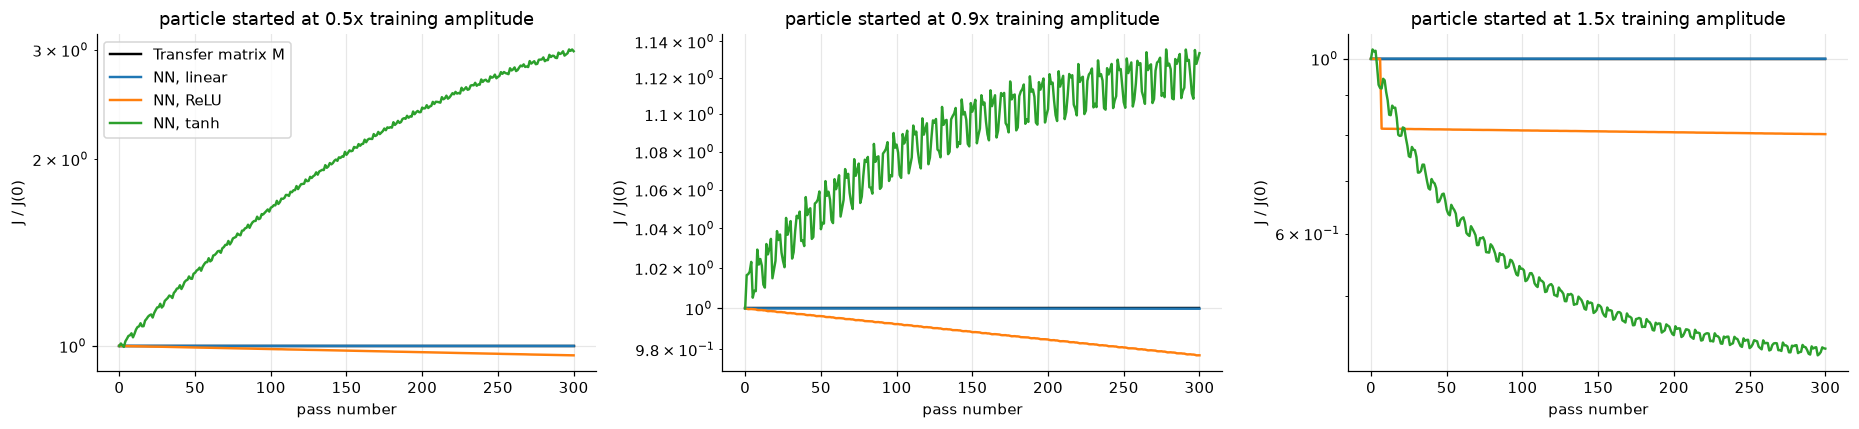

In [15]:
N_PASSES = 300
starts = np.array([[0.5 * X_HALF, 0.0], [0.9 * X_HALF, 0.0], [1.5 * X_HALF, 0.0]])

def track_many(step, z0, n=N_PASSES):
    out = np.empty((n + 1,) + z0.shape)
    out[0] = z0
    for i in range(n):
        out[i + 1] = step(out[i])
    return out

tracks = {"exact": track_many(track_exact, starts)}
for act in ACTS:
    tracks[act] = track_many(models[act].predict, starts)

fig, ax = plt.subplots(1, 4, figsize=(19, 4.8), sharex=True, sharey=True)
for a, key in zip(ax, ["exact"] + ACTS):
    for p, mk in zip(range(len(starts)), ["o", "s", "^"]):
        if key != "exact":
            a.plot(*tracks["exact"][:, p].T, ".", color="lightgray", ms=2)
        a.plot(*tracks[key][:, p].T, mk, color=COLOR[key], ms=2.5, alpha=0.7)
    add_box(a)
    a.set(title=f"{LABEL[key]}: {N_PASSES} passes", xlabel="x [mm]")
ax[0].set_ylabel("x' [mrad]")
lim = 2.0 * X_HALF
for a in ax:
    a.set_xlim(-lim, lim); a.set_ylim(-2.0 * XP_HALF, 2.0 * XP_HALF)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4), sharey=False)
for p, a in enumerate(ax):
    J0 = cs_invariant(starts[p])
    for key in ["exact"] + ACTS:
        a.plot(cs_invariant(tracks[key][:, p]) / J0, color=COLOR[key], lw=1.6, label=LABEL[key])
    a.set(xlabel="pass number", ylabel="J / J(0)", title=f"particle started at {starts[p, 0] / X_HALF:.1f}x training amplitude",
          yscale="log")
ax[0].legend(); plt.tight_layout(); plt.show()

## 10. Transporting a beam

A beam is a distribution of particles. We generate a matched Gaussian beam with rms emittance $\epsilon_{\text{rms}} = 0.4$ mm mrad, whose $3\sigma$ tails reach beyond the training box, transport it through one cell with each model, and compare the output distributions and the rms beam parameters

$$\epsilon_{\text{rms}} = \sqrt{\langle x^2\rangle\langle x'^2\rangle - \langle x x'\rangle^2}, \quad \beta_{\text{rms}} = \langle x^2\rangle/\epsilon_{\text{rms}}, \quad \alpha_{\text{rms}} = -\langle x x'\rangle/\epsilon_{\text{rms}} .$$

**Figure 17** shows the transported beams with their 1σ and 3σ ellipses; **Figure 18** compares the rms parameters after 1 and after 50 passes.

7.6% of the beam particles start outside the training box


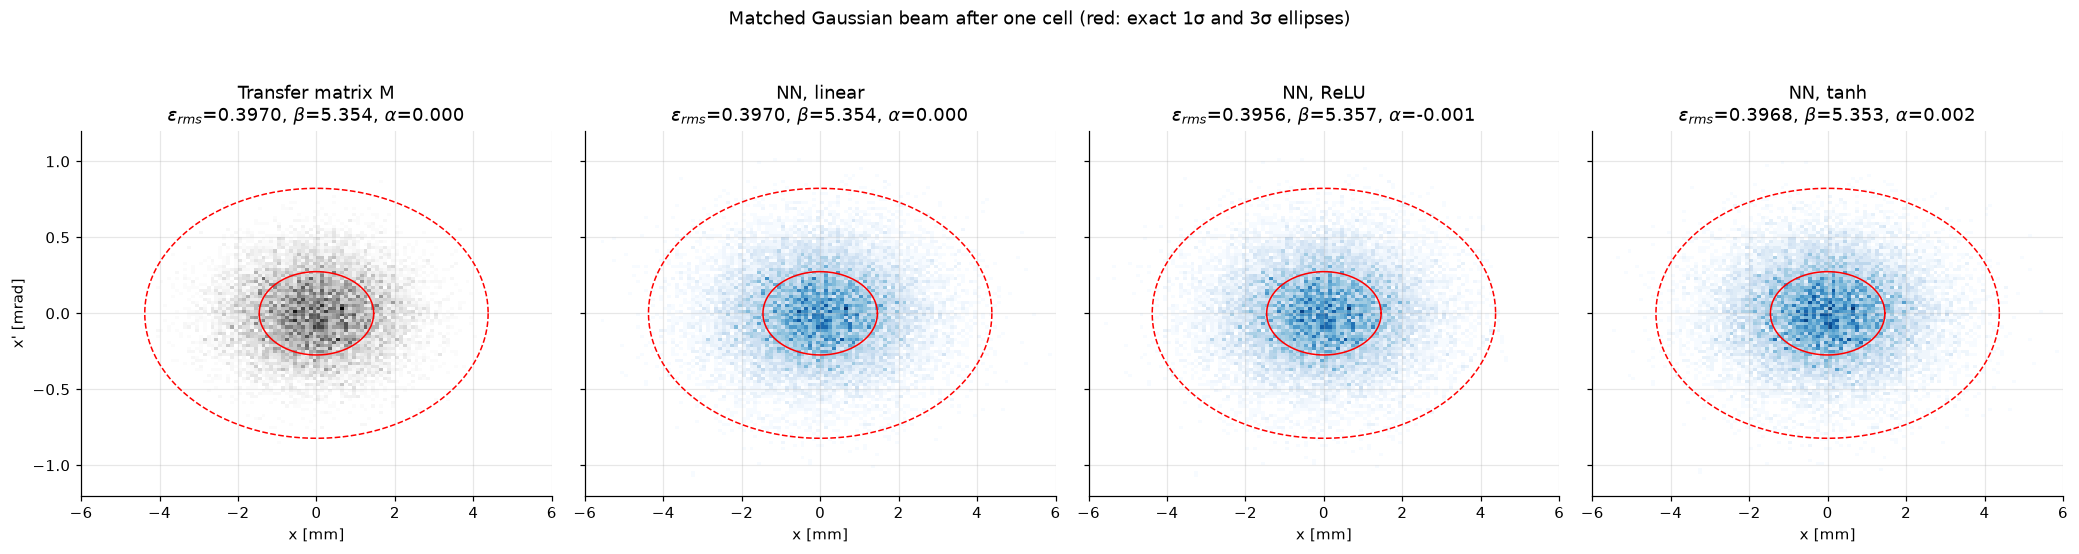

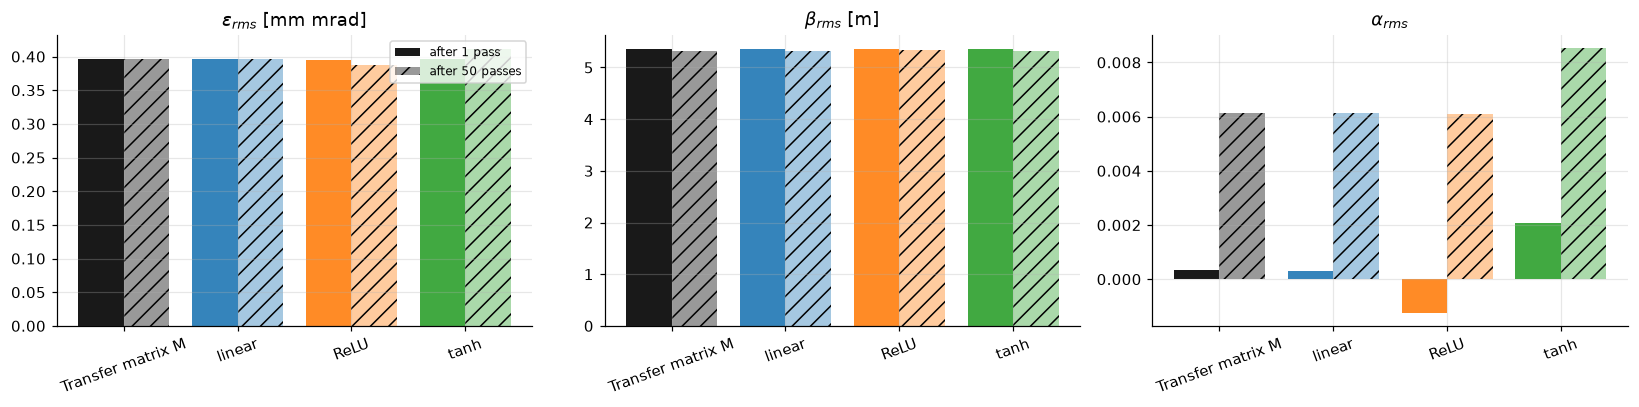

Transfer matrix M emittance after 1 pass 0.3970, after 50 passes 0.3970 mm mrad
NN, linear        emittance after 1 pass 0.3970, after 50 passes 0.3969 mm mrad
NN, ReLU          emittance after 1 pass 0.3956, after 50 passes 0.3874 mm mrad
NN, tanh          emittance after 1 pass 0.3968, after 50 passes 0.4112 mm mrad


In [16]:
EPS_RMS = 0.4
sigma = EPS_RMS * np.array([[BETA, -ALPHA], [-ALPHA, GAMMA]])
beam0 = rng.multivariate_normal([0, 0], sigma, size=20000)
frac_out = np.mean((np.abs(beam0[:, 0]) > X_HALF) | (np.abs(beam0[:, 1]) > XP_HALF))
print(f"{frac_out:.1%} of the beam particles start outside the training box")

def rms_params(z):
    c = np.cov(z.T)
    e = np.sqrt(np.linalg.det(c))
    return {"eps": e, "beta": c[0, 0] / e, "alpha": -c[0, 1] / e}

beam1 = {"exact": track_exact(beam0)}
for act in ACTS:
    beam1[act] = models[act].predict(beam0)

fig, ax = plt.subplots(1, 4, figsize=(19, 4.8), sharex=True, sharey=True)
for a, key in zip(ax, ["exact"] + ACTS):
    a.hist2d(beam1[key][:, 0], beam1[key][:, 1], bins=120, cmap="Greys" if key == "exact" else "Blues",
             range=[[-6, 6], [-1.2, 1.2]], cmin=1)
    for ns in (1, 3):
        a.plot(*ellipse(ALPHA, BETA, EPS_RMS * ns**2).T, color="red", lw=1, ls="--" if ns == 3 else "-")
    p = rms_params(beam1[key])
    a.set(title=f"{LABEL[key]}\n" + rf"$\epsilon_{{rms}}$={p['eps']:.4f}, $\beta$={p['beta']:.3f}, $\alpha$={p['alpha']:.3f}", xlabel="x [mm]")
ax[0].set_ylabel("x' [mrad]")
plt.suptitle("Matched Gaussian beam after one cell (red: exact 1σ and 3σ ellipses)", y=1.04)
plt.tight_layout(); plt.show()

beam50 = {"exact": beam0.copy()}
for key in ACTS:
    beam50[key] = beam0.copy()
for _ in range(50):
    beam50["exact"] = track_exact(beam50["exact"])
    for act in ACTS:
        beam50[act] = models[act].predict(beam50[act])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
keys = ["exact"] + ACTS
for a, par, title in zip(ax, ["eps", "beta", "alpha"], [r"$\epsilon_{rms}$ [mm mrad]", r"$\beta_{rms}$ [m]", r"$\alpha_{rms}$"]):
    v1 = [rms_params(beam1[k])[par] for k in keys]
    v50 = [rms_params(beam50[k])[par] for k in keys]
    xk = np.arange(len(keys))
    a.bar(xk - 0.2, v1, 0.4, color=[COLOR[k] for k in keys], alpha=0.9, label="after 1 pass")
    a.bar(xk + 0.2, v50, 0.4, color=[COLOR[k] for k in keys], alpha=0.4, hatch="//", label="after 50 passes")
    a.set_xticks(xk); a.set_xticklabels([LABEL[k].replace("NN, ", "") for k in keys], rotation=20)
    a.set_title(title)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
for k in keys:
    p1, p50 = rms_params(beam1[k]), rms_params(beam50[k])
    print(f"{LABEL[k]:17s} emittance after 1 pass {p1['eps']:.4f}, after 50 passes {p50['eps']:.4f} mm mrad")

## 11. A non-linear beamline: adding a sextupole

Real lattices contain sextupoles (for chromaticity correction). A thin sextupole gives an angle kick that grows with the square of the offset, $\Delta x' = k_2\, x^2$. Our new beamline is the sextupole followed by the FODO cell:

$$\mathbf{z}_f = \mathbf{M} \begin{pmatrix} x_0 \\ x'_0 + k_2 x_0^2 \end{pmatrix}, \qquad k_2 = 0.04\ \text{mrad/mm}^2 .$$

This map is still symplectic ($\det\mathbf{J} = 1$), but it is no longer linear, so **no transfer matrix can represent it**. A linear network now underfits, while non-linear activations can learn it. We also try a wider network, (32, 32), because 4 units leave little room for curvature.

In [17]:
K2 = 0.04

def track_sext(z):
    z = np.atleast_2d(z)
    kicked = np.c_[z[:, 0], z[:, 1] + K2 * z[:, 0] ** 2]
    return kicked @ M.T

Z1s_train, Z1s_val = track_sext(Z0_train), track_sext(Z0_val)
print(f"sextupole kick at the edge of the box: {K2 * X_HALF**2:.3f} mrad (angle range of the box: {XP_HALF:.3f} mrad)")

nl_models = {}
for act in ACTS:
    for hidden in [(4, 4), (32, 32)]:
        m = make_mlp(act, hidden=hidden).fit(Z0_train, Z1s_train)
        nl_models[(act, hidden)] = m
        rmse = np.sqrt(np.mean((m.predict(Z0_val) - Z1s_val) ** 2))
        print(f"{LABEL[act]:11s} {str(hidden):8s} validation RMSE = {rmse:.2e}")

sextupole kick at the edge of the box: 0.360 mrad (angle range of the box: 0.564 mrad)
NN, linear  (4, 4)   validation RMSE = 3.29e-01
NN, linear  (32, 32) validation RMSE = 3.29e-01
NN, ReLU    (4, 4)   validation RMSE = 8.25e-02


NN, ReLU    (32, 32) validation RMSE = 3.72e-03


NN, tanh    (4, 4)   validation RMSE = 8.24e-03


NN, tanh    (32, 32) validation RMSE = 2.09e-03


**Figure 19:** the image of the training box and of a regular grid under the true non-linear map (black) and the (32, 32) surrogates, with the $\log_{10}$ error map below. **Figure 20** compares validation error by activation and width.

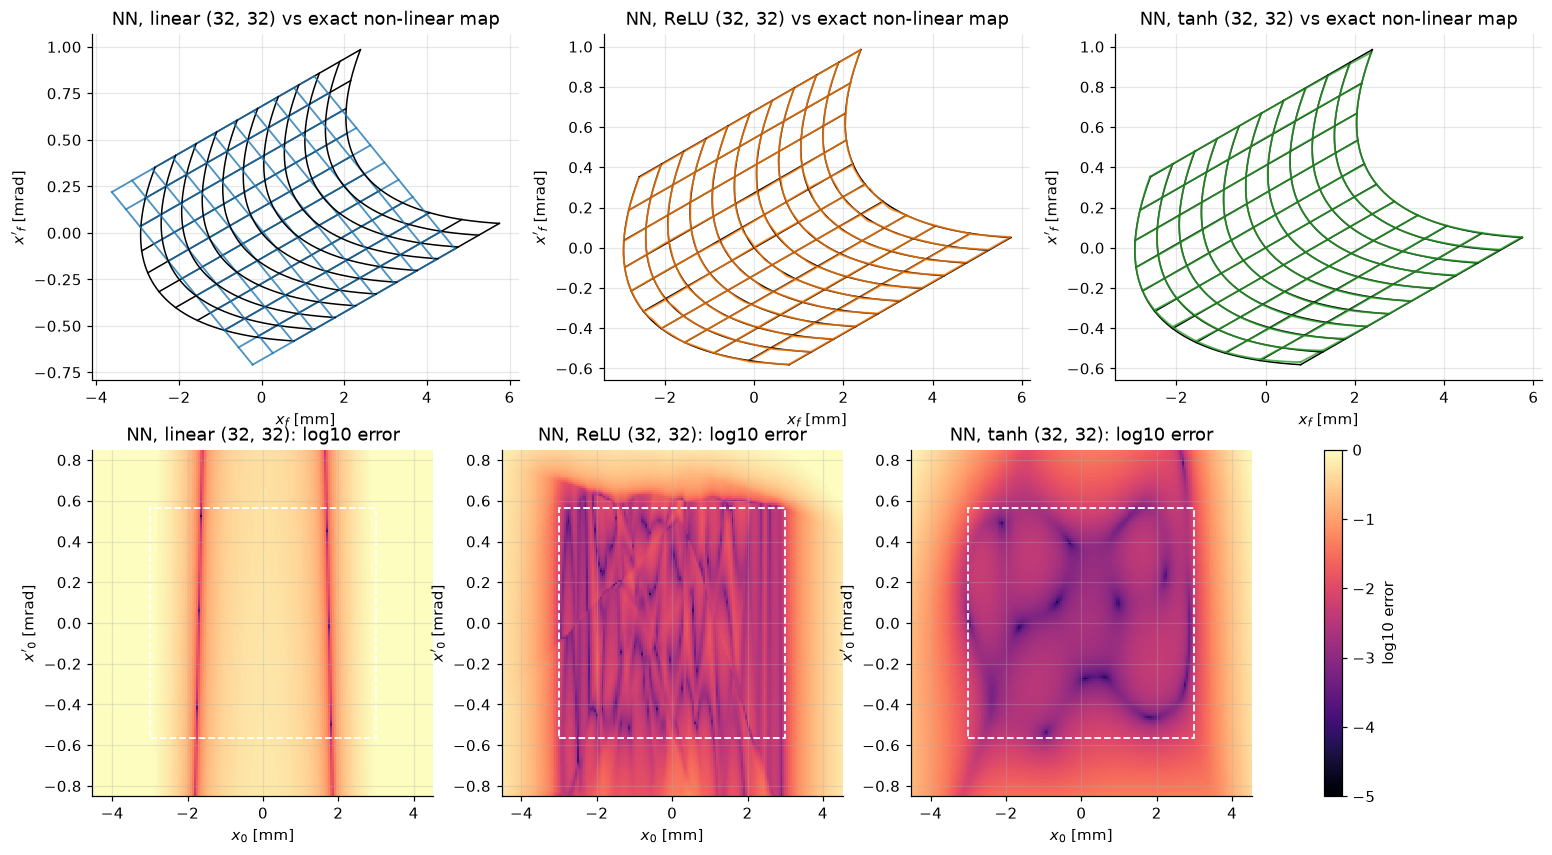

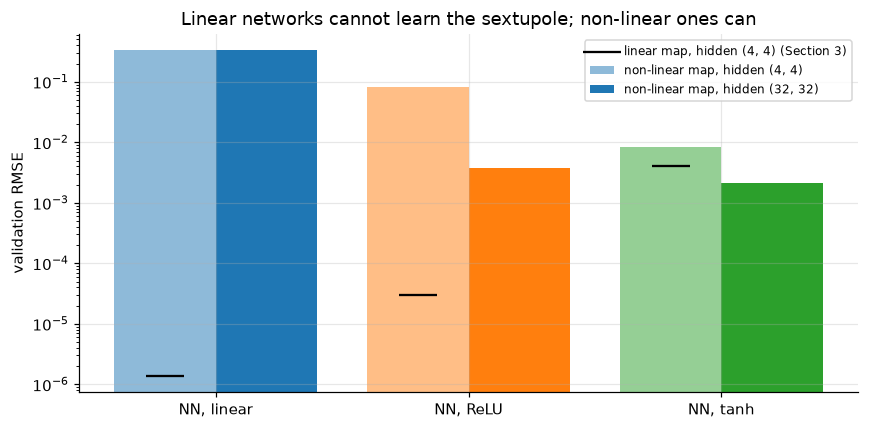

In [18]:
lines1 = grid_lines(scale=1.0, n_lines=11)
XX1, PP1, ZG1 = phase_grid(scale=1.5, n=181)
exact_nl = track_sext(ZG1)
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for k, act in enumerate(ACTS):
    m = nl_models[(act, (32, 32))]
    for ln in lines1:
        ax[0, k].plot(*track_sext(ln).T, color="black", lw=1)
        ax[0, k].plot(*m.predict(ln).T, color=COLOR[act], lw=1.2, alpha=0.8)
    ax[0, k].set(title=f"{LABEL[act]} (32, 32) vs exact non-linear map", xlabel="$x_f$ [mm]", ylabel="$x'_f$ [mrad]")
    err = np.linalg.norm(m.predict(ZG1) - exact_nl, axis=1).reshape(XX1.shape)
    im = ax[1, k].pcolormesh(XX1, PP1, np.log10(err + 1e-12), cmap="magma", vmin=-5, vmax=0, shading="auto")
    add_box(ax[1, k], color="white")
    ax[1, k].set(title=f"{LABEL[act]} (32, 32): log10 error", xlabel="$x_0$ [mm]", ylabel="$x'_0$ [mrad]")
plt.colorbar(im, ax=ax[1, :], label="log10 error")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
xk = np.arange(len(ACTS))
for off, hidden, alpha in [(-0.2, (4, 4), 0.5), (0.2, (32, 32), 1.0)]:
    vals = [np.sqrt(np.mean((nl_models[(a, hidden)].predict(Z0_val) - Z1s_val) ** 2)) for a in ACTS]
    lin_vals = [np.sqrt(np.mean((models[a].predict(Z0_val) - Z1_val) ** 2)) for a in ACTS]
    ax.bar(xk + off, vals, 0.4, color=[COLOR[a] for a in ACTS], alpha=alpha, label=f"non-linear map, hidden {hidden}")
ax.scatter(xk - 0.2, lin_vals, marker="_", s=600, color="k", zorder=5, label="linear map, hidden (4, 4) (Section 3)")
ax.set_yscale("log"); ax.set_xticks(xk); ax.set_xticklabels([LABEL[a] for a in ACTS])
ax.set(ylabel="validation RMSE", title="Linear networks cannot learn the sextupole; non-linear ones can")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Figure 21: non-linear tracking.** With the sextupole the exact phase-space portrait is no longer a set of ellipses: orbits are distorted and, beyond the dynamic aperture, particles escape. We track 8 particles for 300 passes with the exact map and with the (32, 32) tanh and ReLU surrogates (particles that leave the plotted region are dropped).

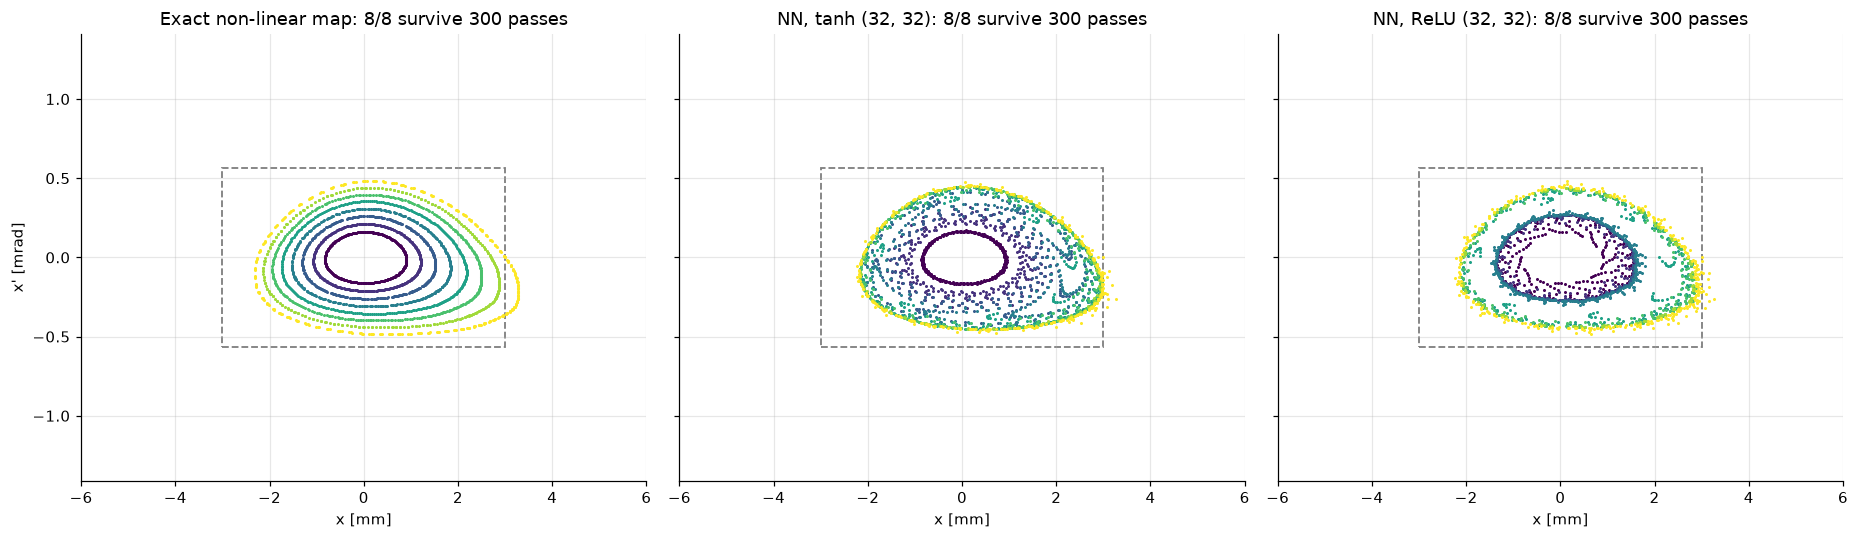

In [19]:
starts_nl = np.c_[np.linspace(0.3, 1.0, 8) * X_HALF, np.zeros(8)]

def track_bounded(step, z0, n=N_PASSES, limit=4 * X_HALF):
    out = np.full((n + 1,) + z0.shape, np.nan)
    out[0] = z0
    z = z0.copy()
    alive = np.ones(len(z0), bool)
    for i in range(n):
        z = step(z)
        alive &= np.all(np.isfinite(z), axis=1) & (np.abs(z[:, 0]) < limit)
        z[~alive] = 0.0
        out[i + 1][alive] = z[alive]
    return out, alive

fig, ax = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for a, (key, step) in zip(ax, [("exact", track_sext), ("tanh", nl_models[("tanh", (32, 32))].predict),
                               ("relu", nl_models[("relu", (32, 32))].predict)]):
    tr, alive = track_bounded(step, starts_nl)
    cols = plt.cm.viridis(np.linspace(0, 1, len(starts_nl)))
    for p in range(len(starts_nl)):
        a.plot(*tr[:, p].T, ".", ms=2, color=cols[p])
    add_box(a)
    a.set(title=f"{'Exact non-linear map' if key == 'exact' else LABEL[key] + ' (32, 32)'}: {alive.sum()}/8 survive {N_PASSES} passes",
          xlabel="x [mm]")
ax[0].set_ylabel("x' [mrad]")
for a in ax:
    a.set_xlim(-2 * X_HALF, 2 * X_HALF); a.set_ylim(-2.5 * XP_HALF, 2.5 * XP_HALF)
plt.tight_layout(); plt.show()

## 12. How much data and how many units?

**Figure 22** repeats the training for the linear map and the sextupole map with different numbers of tracking pairs and hidden widths, and plots the validation error (median of 3 random seeds).

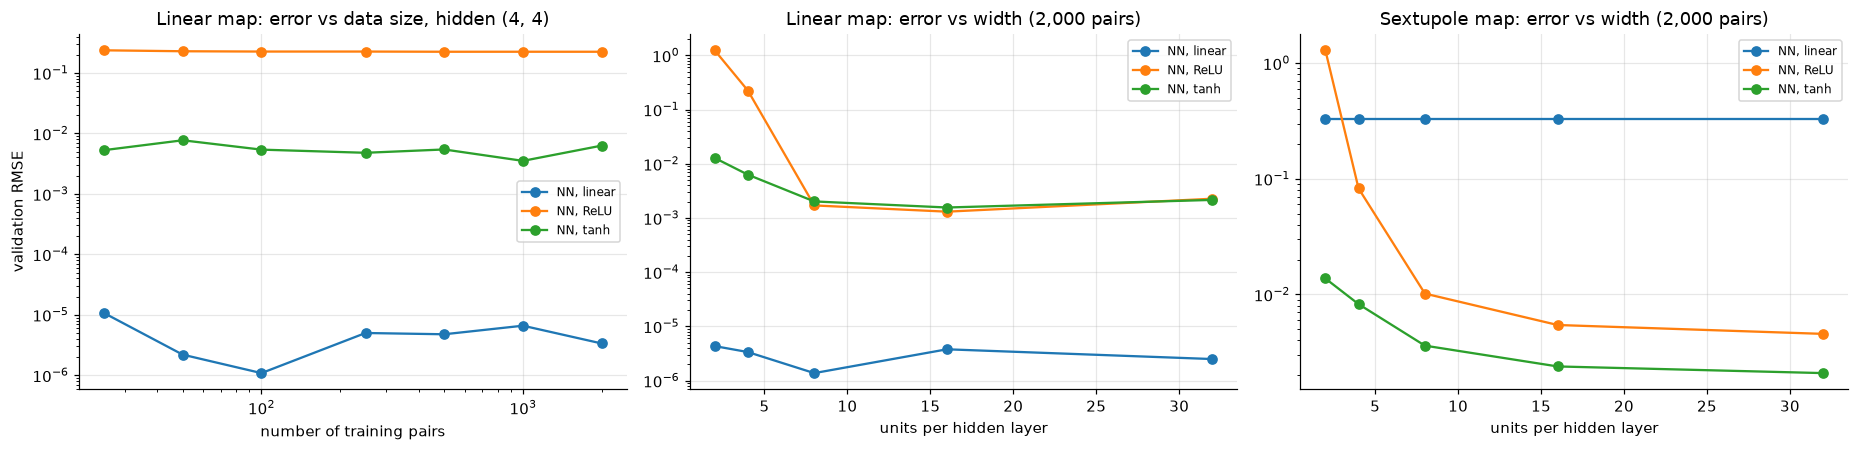

In [20]:
sizes = [25, 50, 100, 250, 500, 1000, 2000]
widths = [2, 4, 8, 16, 32]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for act in ACTS:
    errs = []
    for n in sizes:
        e = [np.sqrt(np.mean((make_mlp(act, seed=s).fit(Z0_train[:n], Z1_train[:n]).predict(Z0_val) - Z1_val) ** 2)) for s in (1, 2, 3)]
        errs.append(np.median(e))
    ax[0].loglog(sizes, errs, "o-", color=COLOR[act], label=LABEL[act])
    errs_w, errs_ws = [], []
    for w in widths:
        e = [np.sqrt(np.mean((make_mlp(act, hidden=(w, w), seed=s).fit(Z0_train, Z1_train).predict(Z0_val) - Z1_val) ** 2)) for s in (1, 2, 3)]
        es = [np.sqrt(np.mean((make_mlp(act, hidden=(w, w), seed=s).fit(Z0_train, Z1s_train).predict(Z0_val) - Z1s_val) ** 2)) for s in (1, 2, 3)]
        errs_w.append(np.median(e)); errs_ws.append(np.median(es))
    ax[1].semilogy(widths, errs_w, "o-", color=COLOR[act], label=LABEL[act])
    ax[2].semilogy(widths, errs_ws, "o-", color=COLOR[act], label=LABEL[act])
ax[0].set(xlabel="number of training pairs", ylabel="validation RMSE", title="Linear map: error vs data size, hidden (4, 4)")
ax[1].set(xlabel="units per hidden layer", title="Linear map: error vs width (2,000 pairs)")
ax[2].set(xlabel="units per hidden layer", title="Sextupole map: error vs width (2,000 pairs)")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 13. Summary

In [21]:
rows = []
for act in ACTS:
    m = models[act]
    rmse_in = np.sqrt(np.mean((m.predict(Z0_val) - Z1_val) ** 2))
    e3 = ellipse(ALPHA, BETA, EPS_BOX * 9, n=400)
    err3 = np.mean(np.linalg.norm(m.predict(e3) - track_exact(e3), axis=1))
    d_in = detJ_maps[act].ravel()[inside]
    J_end = cs_invariant(tracks[act][-1, 1]) / cs_invariant(starts[1])
    eps50 = rms_params(beam50[act])["eps"] / rms_params(beam50["exact"])["eps"]
    nl = np.sqrt(np.mean((nl_models[(act, (32, 32))].predict(Z0_val) - Z1s_val) ** 2))
    rows.append((LABEL[act], rmse_in, err3, np.abs(d_in - 1).max(), J_end, eps50, nl))

hdr = ("Model", "RMSE in box", "error at 3x", "max|detJ-1| in box", "J after 300 passes", "eps ratio, 50 passes", "sextupole RMSE (32,32)")
print(" | ".join(f"{h:>20s}" for h in hdr))
for r in rows:
    print(f"{r[0]:>20s} | " + " | ".join(f"{v:>20.3e}" if i < 3 or i == 5 else f"{v:>20.4f}" for i, v in enumerate(r[1:])))

               Model |          RMSE in box |          error at 3x |   max|detJ-1| in box |   J after 300 passes | eps ratio, 50 passes | sextupole RMSE (32,32)
          NN, linear |            1.388e-06 |            5.278e-06 |            5.923e-07 |               0.9998 |               1.0000 |            3.294e-01
            NN, ReLU |            2.962e-05 |            1.385e+00 |            1.000e+00 |               0.9772 |               0.9760 |            3.721e-03
            NN, tanh |            4.001e-03 |            3.191e-01 |            7.887e-02 |               1.1335 |               1.0359 |            2.088e-03


### What the figures show

* **A linear network is a transfer matrix.** With identity activations the three layers collapse into one matrix, which the network learns to near machine precision. It is exact everywhere, conserves area, extrapolates perfectly and tracks forever, but it cannot represent anything non-linear, such as the sextupole map.
* **Small validation error is not enough.** Inside the training box the ReLU network is accurate to about $3 \times 10^{-5}$ and the tanh network to about $4 \times 10^{-3}$, yet their phase-space geometry is wrong: kinks (ReLU), smooth bending (tanh), $\det\mathbf{J} \ne 1$, and large errors outside the box. Over many passes these errors accumulate: in 300 passes the tanh surrogate pushes a particle at half the training amplitude out to three times its Courant-Snyder invariant.
* **Small ReLU networks are fragile.** The accurate ReLU result above came from a favorable seed: 5 of 10 seeds gave errors of 0.2 or more, while tanh stayed between 0.004 and 0.011.
* **A good surrogate of a non-linear map is still not symplectic.** With the sextupole, the (32, 32) networks fit the map to about $2$–$4 \times 10^{-3}$, but over 300 passes their orbits scatter where the exact orbits lie on clean closed curves.
* **Each activation leaves its own fingerprint.** ReLU produces a piecewise-affine map with flat regions where the Jacobian can vanish; tanh is smooth near the core but flattens as its units saturate at large amplitude.
* **Match the model to the physics.** When the map is linear, use a linear model. When it is non-linear, smooth activations with enough units learn it well inside the training region, and the training region must cover the beam you care about.
* **Physics-aware architectures** (slide 17) go further: symplectic or Hamiltonian networks conserve $\det\mathbf{J} = 1$ by construction.

### Exercises

1. Change the FODO focal length `F_QUAD` (keep $|\text{tr}\,\mathbf{M}| < 2$) and watch the ellipses and the tracking change.
2. Train the ReLU and tanh networks on a box 3x larger. How do Figures 10 and 15 change?
3. Add 10 µm and 10 µrad Gaussian noise to the training targets. Which network suffers most?
4. Increase `K2` until the exact map loses particles inside the training box. Can the surrogates still learn it?
5. Replace `lbfgs` by `adam` in `make_mlp` and compare the accuracy in Section 3.